
# Experiment 1 — Camera–LiDAR Geometric Projection and Association

## Objective
Evaluate a custom-trained PointPillars detector together with a YOLOv8 camera detector. Project LiDAR 3D bounding boxes into the camera image and associate them with compatible 2D detections.

## Workflow
1. Initialize the detection models.
2. Load a Waymo frame and its camera calibration.
3. Run a single-frame sanity check.
4. Execute the full experiment and save the results.
5. Analyze association quality, projection coverage, and processing time.

**Implementation:** reusable functions are maintained in `src/`, while the experiment runner and plotting scripts are maintained in `experiments/`.


## Initial Setup and Model Initialization

### Purpose of the initial setup

Load the custom-trained PointPillars detector, the camera detector,
and the functions required for geometric projection and association.
The first checks verify that the data, calibration, and models are
available before running the full experiment.


In [ ]:
# Imports PointPillars loading/prediction, camera model loading/prediction, and matching utilities.
from src.models.pointpillars import load_pointpillars, predict_lidar
from src.models.camera_detector import load_camera_detector, predict_camera
from src.fusion.matching import box_iou, merge_camera_boxes, greedy_match

detector, lidar_model, cfg, device = load_pointpillars()
camera_model = load_camera_detector("yolov8n.pt")

print("Experiment 1 models loaded.")
print("LiDAR classes:", cfg["model"]["class_names"])
print("Device:", device)

Loaded checkpoint from segment 24
Device: cpu
Classes: ['vehicle', 'pedestrian', 'cyclist', 'sign']


ValueError: not enough values to unpack (expected 5, got 4)

In [44]:
# Imports projection, camera geometry and association functions.
from src.fusion.projection import project_lidar_box, load_camera_geometry
from src.fusion.association import associate_detections

print("Projection and association modules imported")

Projection and association modules imported


In [55]:
# Imports paths, timing and Waymo data-loading utilities.
from pathlib import Path
import time
from src.data.waymo_fusion_data import (
    load_camera_calibration,
    available_frame_indices,
    load_fusion_frame,
)

local = Path("/content/waymo_fusion_converted/10017090168044687777_6380_000_6400_000")
backup = Path("/content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_workspace_backup/converted_context/10017090168044687777_6380_000_6400_000")

def timed(label, fn):
    start = time.time()
    print(f"Starting: {label}", flush=True)
    result = fn()
    print(f"Finished: {label} in {time.time()-start:.2f}s", flush=True)
    return result

context_dir = local

calibration = timed(
    "Load calibration",
    lambda: load_camera_calibration(context_dir)
)
print("Calibration keys:", list(calibration.keys()), flush=True)

frame_indices = timed(
    "Find matching frame indices",
    lambda: available_frame_indices(context_dir)
)

frame = timed(
    "Load first camera + LiDAR frame",
    lambda: load_fusion_frame(context_dir, frame_indices[0])
)

print("Image size:", frame["image"].size)
print("Combined LiDAR points:", frame["points"].shape)
print("Camera timestamp:", frame["camera_timestamp"])
print("LiDAR timestamps:", frame["lidar1_timestamp"], frame["lidar2_timestamp"])


Starting: Load calibration
Finished: Load calibration in 0.00s
Calibration keys: ['camera_name', 'context', 'intrinsic', 'extrinsic', 'width', 'height', 'rolling_shutter_direction']
Starting: Find matching frame indices
Frames with camera + both LiDAR returns: 198
First available frame indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Finished: Find matching frame indices in 0.01s
Starting: Load first camera + LiDAR frame
Finished: Load first camera + LiDAR frame in 0.02s
Image size: (1920, 1280)
Combined LiDAR points: (165170, 5)
Camera timestamp: 1550083467346370
LiDAR timestamps: 1550083467346370 1550083467346370


In [57]:
# Imports the frame runner and converted-context utility.
from src.fusion.runner import run_fusion_frame
from src.data.waymo_fusion_data import ensure_converted_context

context_dir = ensure_converted_context()

result = run_fusion_frame(
    frame_idx=0,
    detector=detector,
    lidar_model=lidar_model,
    cfg=cfg,
    camera_model=camera_model,
    context_dir=context_dir,
    save_visualization=False,
)

for key, value in result.items():
    if key not in {"iou_matrix", "matches"}:
        print(f"{key}: {value}")


Converted context ready: /content/waymo_fusion_converted/10017090168044687777_6380_000_6400_000
frame_idx: 0
num_points_raw: 165170
num_points_model: 165170
num_lidar_detections: 360
num_camera_detections: 3
num_camera_candidates: 3
num_projected_boxes: 194
num_matches: 1
mean_matched_iou: 0.5682364458913775
lidar_inference_seconds: 2.9224795669997548
camera_inference_seconds: 0.19430414700036636
total_seconds: 4.1095278579996375
csv_path: /content/drive/MyDrive/Colab Notebooks/3DPerception/project/experiments/experiment_1_results/experiment_1_detections.csv
visualization_path: None


## Diagnostic Investigations: Calibration and Projection.

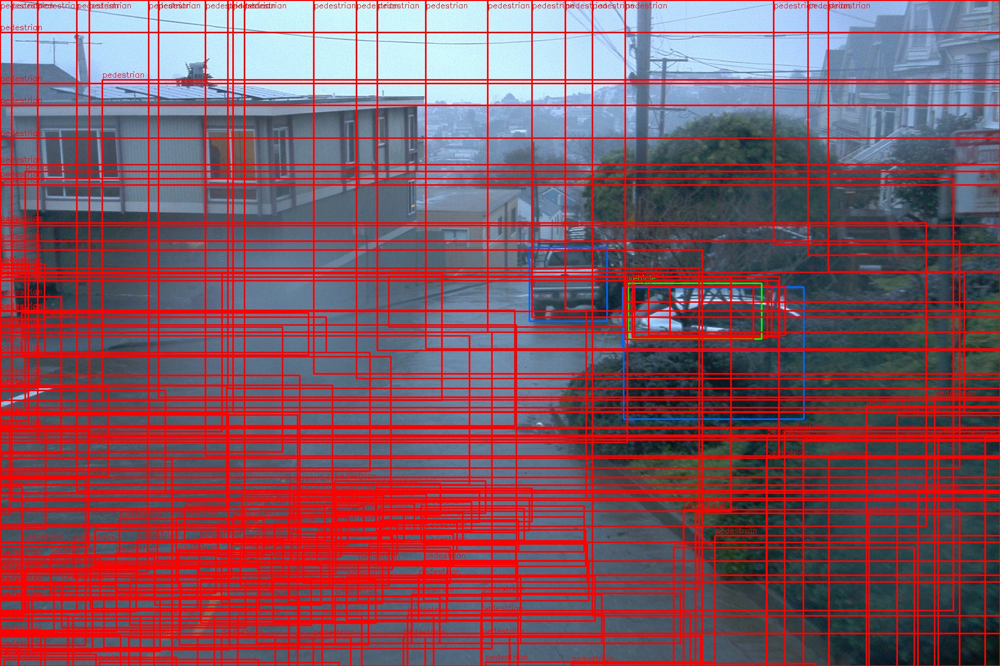

In [47]:
# Displays the visualization produced by the earlier fusion run.
from IPython.display import display, Image

display(Image(filename=result["visualization_path"]))


In [54]:
# Imports the runner module, LiDAR prediction function and frame loader.
import src.fusion.runner as runner_module
from src.models.pointpillars import predict_lidar
from src.data.waymo_fusion_data import load_fusion_frame
import numpy as np

frame = load_fusion_frame(context_dir, 0)
points_raw = frame["points"]

points_model = runner_module._finite_points(points_raw, cfg)

lidar_detections = predict_lidar(
    detector, lidar_model, points_model, cfg
)

print("LiDAR detections:", len(lidar_detections))
print("First detection:", lidar_detections[0] if lidar_detections else "None")


LiDAR detections: 360
First detection: {'box': [np.float64(-18.974046856164932), np.float64(-5.577946454286575), 1.0217163562774658, 5.370831342547175, 2.0798944550037923, 2.599069883957606, 0.009867600155684001], 'label': 0, 'score': 0.2222018986940384}


In [58]:
# Imports Counter and NumPy for counting and analyzing detections.
from collections import Counter
import numpy as np

scores = np.array([d["score"] for d in lidar_detections], dtype=float)
boxes = np.array([d["box"] for d in lidar_detections], dtype=float)
labels = [int(d["label"]) for d in lidar_detections]

print("Class distribution:")
for label, count in sorted(Counter(labels).items()):
    print(f"{cfg['model']['class_names'][label]}: {count}")

print("\nScore percentiles:")
print(np.percentile(scores, [0, 25, 50, 75, 90, 95, 99, 100]))

print("\nDetections above score thresholds:")
for threshold in [0.1, 0.2, 0.3, 0.5, 0.7]:
    print(f"score >= {threshold:.1f}: {(scores >= threshold).sum()}")

print("\nBox dimensions (dx, dy, dz) percentiles:")
print(np.percentile(boxes[:, 3:6], [0, 25, 50, 75, 95, 100], axis=0))

print("\nBox centers (cx, cy, cz) percentiles:")
print(np.percentile(boxes[:, :3], [0, 25, 50, 75, 95, 100], axis=0))


Class distribution:
vehicle: 32
pedestrian: 328

Score percentiles:
[    0.20047     0.22721      0.2505     0.26527     0.28474     0.29656     0.32895     0.39234]

Detections above score thresholds:
score >= 0.1: 360
score >= 0.2: 360
score >= 0.3: 15
score >= 0.5: 0
score >= 0.7: 0

Box dimensions (dx, dy, dz) percentiles:
[[    0.91291     0.92525      1.6065]
 [     1.0906     0.99552      1.7487]
 [     1.1146      1.0058      1.7865]
 [     1.1541      1.0167      1.8156]
 [     4.6291      1.9468      1.9015]
 [     6.6612      2.4556      2.5991]]

Box centers (cx, cy, cz) percentiles:
[[    -22.978     -7.6292     0.51342]
 [      6.869     0.36595      0.7389]
 [     8.3999      3.8702     0.81941]
 [     10.399      7.4322     0.90582]
 [      13.32      10.398     0.93873]
 [     33.397      16.952      1.0796]]


LiDAR detections retained: 15
Boxes successfully projected: 4


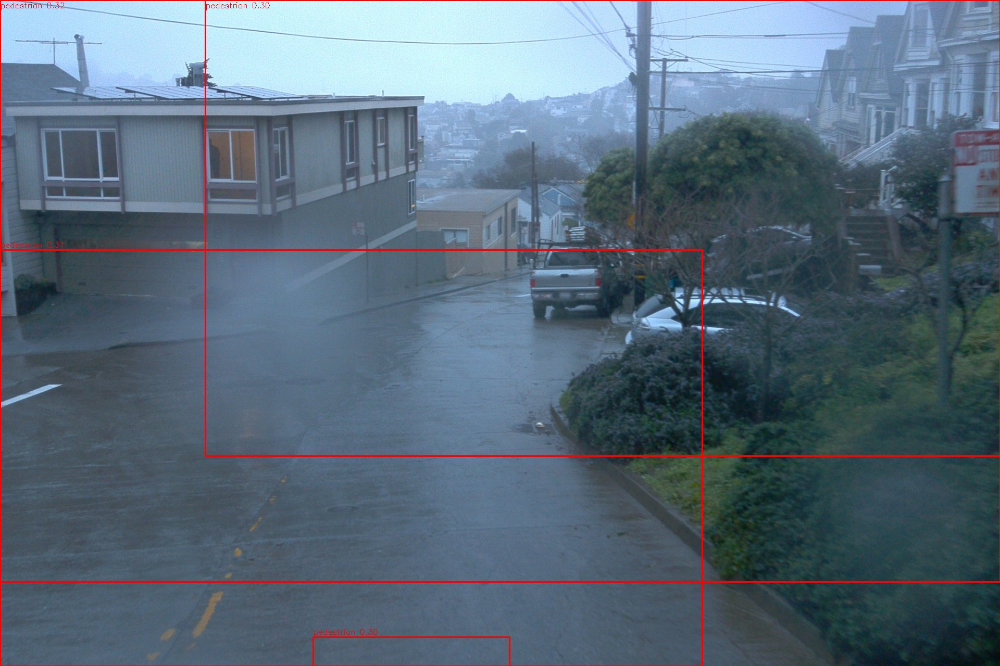

In [59]:
# Imports OpenCV and display utilities.
import cv2
import numpy as np
from IPython.display import display, Image
from pathlib import Path

# Reconstruct the frame image.
vis = cv2.cvtColor(np.asarray(frame["image"]), cv2.COLOR_RGB2BGR)

# Keep only detections with score >= 0.30.
threshold = 0.30
kept = [d for d in lidar_detections if d["score"] >= threshold]

geometry = load_camera_geometry(calibration)

projected = []
for d in kept:
    box2d = project_lidar_box(
        d["box"],
        points_raw,
        geometry["T_camera_vehicle"],
        geometry["K"],
        geometry["dist"],
        geometry["image_width"],
        geometry["image_height"],
    )
    projected.append((d, box2d))

for d, box2d in projected:
    if box2d is None:
        continue

    x1, y1, x2, y2 = map(int, box2d)
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 0, 255), 2)

    class_name = cfg["model"]["class_names"][int(d["label"])]
    text = f"{class_name} {d['score']:.2f}"
    cv2.putText(
        vis, text, (x1, max(15, y1 - 5)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1,
    )

out_path = "/content/frame_000_lidar_conf030.jpg"
cv2.imwrite(out_path, vis)

print("LiDAR detections retained:", len(kept))
print("Boxes successfully projected:", sum(b is not None for _, b in projected))
display(Image(filename=out_path))


In [61]:
# Prints calibration information - establishes the calibration parameters used for projection.
import numpy as np

print("=== Calibration ===")
print("Image size:", geometry["image_width"], "x", geometry["image_height"])
print("Intrinsic matrix K:\n", geometry["K"])
print("Distortion coefficients:", geometry["dist"])
print("T_camera_vehicle:\n", geometry["T_camera_vehicle"])

T = geometry["T_camera_vehicle"]
print("\nRotation determinant:", np.linalg.det(T[:3, :3]))
print("Last row:", T[3, :])

print("\n=== High-confidence LiDAR predictions ===")
for d in sorted(lidar_detections, key=lambda d: d["score"], reverse=True)[:10]:
    print(
        "class =", cfg["model"]["class_names"][int(d["label"])],
        "| score =", round(float(d["score"]), 3),
        "| box =", np.round(d["box"], 3).tolist()
    )
T_vehicle_camera = np.asarray(calibration["extrinsic"], dtype=np.float64)
T_camera_vehicle = np.linalg.inv(T_vehicle_camera)

=== Calibration ===
Image size: 1920 x 1280
Intrinsic matrix K:
 [[     2059.6           0      952.41]
 [          0      2059.6      634.59]
 [          0           0           1]]
Distortion coefficients: [   0.035453     -0.3383   1.923e-05  0.00071386           0]
T_camera_vehicle:
 [[    0.99998  -0.0032445   -0.005697     -1.5271]
 [  0.0031421     0.99983   -0.017897    0.057055]
 [  0.0057541    0.017878     0.99982     -2.1238]
 [          0           0           0           1]]

Rotation determinant: 0.9999999999999999
Last row: [          0           0           0           1]

=== High-confidence LiDAR predictions ===
class = vehicle | score = 0.392 | box = [-17.727, -5.301, 0.931, 5.171, 1.931, 2.197, 0.005]
class = vehicle | score = 0.389 | box = [-8.761, 0.277, 0.869, 4.854, 2.215, 1.833, 0.013]
class = vehicle | score = 0.365 | box = [-18.054, -5.67, 1.046, 5.627, 2.025, 2.523, 0.022]
class = vehicle | score = 0.335 | box = [-18.15, -5.295, 0.955, 5.271, 1.962, 2.24, 0

Points selected: 81572
Points in front of camera: 76225
Points projected inside image: 24285


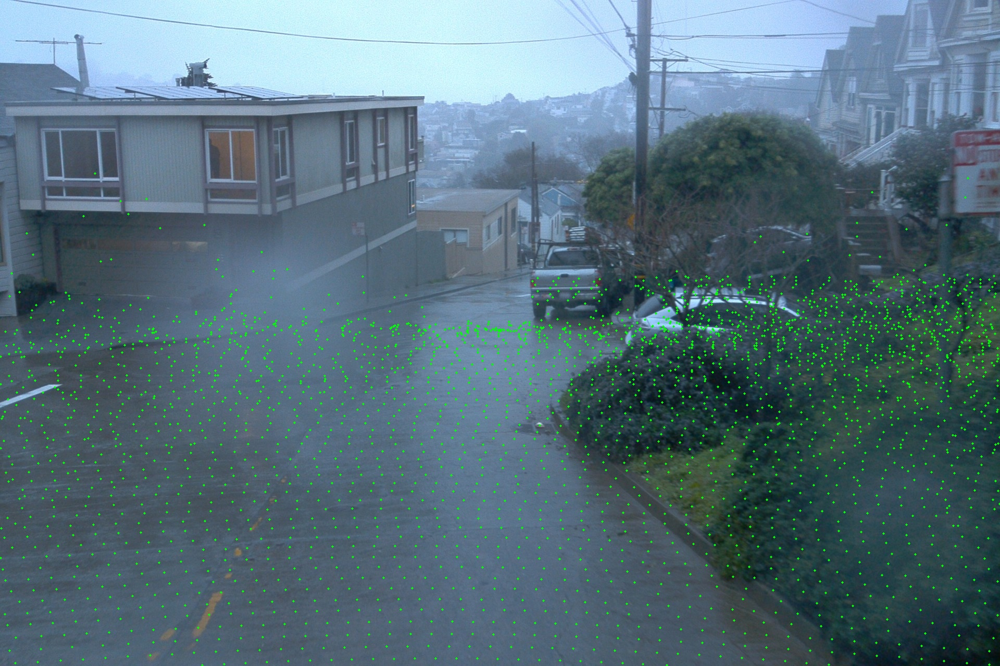

In [62]:
# Tests an image overlay or projection visualization - it demonstrates how projected points or boxes align with the camera image.
import cv2
import numpy as np
from IPython.display import display, Image

# Sample raw vehicle-frame points in front of the vehicle.
pts = points_raw[np.isfinite(points_raw[:, :3]).all(axis=1)]
pts = pts[
    (pts[:, 0] > 1) & (pts[:, 0] < 30) &
    (np.abs(pts[:, 1]) < 12)
]

# Transform vehicle-frame points to camera coordinates.
T = geometry["T_camera_vehicle"]
points_h = np.column_stack([pts[:, :3], np.ones(len(pts))])
camera_xyz = (T @ points_h.T).T[:, :3]

# Convert to the OpenCV camera convention used by the current projection.
points_cv = np.column_stack([
    -camera_xyz[:, 1],
    -camera_xyz[:, 2],
    camera_xyz[:, 0],
])

front = points_cv[:, 2] > 0.1
points_cv = points_cv[front]

uv, _ = cv2.projectPoints(
    points_cv,
    np.zeros(3), np.zeros(3),
    geometry["K"], geometry["dist"]
)
uv = uv.reshape(-1, 2)

inside = (
    (uv[:, 0] >= 0) & (uv[:, 0] < geometry["image_width"]) &
    (uv[:, 1] >= 0) & (uv[:, 1] < geometry["image_height"])
)
uv = uv[inside]

vis = cv2.cvtColor(np.asarray(frame["image"]), cv2.COLOR_RGB2BGR)
for u, v in uv[::max(1, len(uv)//3000)]:
    cv2.circle(vis, (int(u), int(v)), 2, (0, 255, 0), -1)

out_path = "/content/frame_000_projected_points.jpg"
cv2.imwrite(out_path, vis)

print("Points selected:", len(pts))
print("Points in front of camera:", len(points_cv))
print("Points projected inside image:", len(uv))
display(Image(filename=out_path))


In [63]:
# Calls the projection function on selected detections.
import numpy as np
from src.fusion.projection import project_lidar_box

vehicle_dets = [
    d for d in lidar_detections
    if cfg["model"]["class_names"][int(d["label"])] == "vehicle"
]
vehicle_dets.sort(key=lambda d: d["score"], reverse=True)

for d in vehicle_dets[:5]:
    box2d = project_lidar_box(
        d["box"], points_raw,
        geometry["T_camera_vehicle"],
        geometry["K"], geometry["dist"],
        geometry["image_width"], geometry["image_height"],
    )
    print(
        "score:", round(float(d["score"]), 3),
        "3D box:", np.round(d["box"], 2).tolist(),
        "projected box:", box2d,
    )


score: 0.392 3D box: [-17.73, -5.3, 0.93, 5.17, 1.93, 2.2, 0.01] projected box: None
score: 0.389 3D box: [-8.76, 0.28, 0.87, 4.85, 2.22, 1.83, 0.01] projected box: None
score: 0.365 3D box: [-18.05, -5.67, 1.05, 5.63, 2.03, 2.52, 0.02] projected box: None
score: 0.335 3D box: [-18.15, -5.29, 0.96, 5.27, 1.96, 2.24, 0.01] projected box: None
score: 0.307 3D box: [-18.49, -5.61, 1.03, 5.23, 1.99, 2.58, 0.03] projected box: None


In [64]:
# Inspects the first vehicle detection and its box parameters.
import numpy as np

d = vehicle_dets[0]
box = np.asarray(d["box"], dtype=float)
x, y, _, sx, sy, _, heading = box

dx = points_raw[:, 0] - x
dy = points_raw[:, 1] - y
c, s = np.cos(heading), np.sin(heading)

local_x = dx * c + dy * s
local_y = -dx * s + dy * c

inside = (
    (np.abs(local_x) <= sx / 2) &
    (np.abs(local_y) <= sy / 2) &
    np.isfinite(points_raw[:, :3]).all(axis=1)
)
selected = points_raw[inside]

print("Detection score:", float(d["score"]))
print("Box center:", box[:3])
print("Box dimensions:", box[3:6])
print("LiDAR points inside BEV footprint:", len(selected))

if len(selected):
    z_low, z_high = np.percentile(selected[:, 2], [5, 95])
    print("Observed point z range (5th–95th percentile):", z_low, z_high)

# Transform the predicted box center into camera coordinates.
center_h = np.append(box[:3], 1.0)
center_camera = geometry["T_camera_vehicle"] @ center_h
center_cv = np.array([
    -center_camera[1], -center_camera[2], center_camera[0]
])
print("Box center in current camera convention:", center_cv)


Detection score: 0.392341285943985
Box center: [    -17.727     -5.3005     0.93077]
Box dimensions: [     5.1713      1.9313      2.1968]
LiDAR points inside BEV footprint: 723
Observed point z range (5th–95th percentile): 1.8725242614746094 2.874106597900391
Box center in current camera convention: [     5.3149        1.39     -19.242]


In [65]:
# Examines the transformation matrix used to map vehicle coordinates.
import numpy as np

T = geometry["T_camera_vehicle"]
center_h = np.append(box[:3], 1.0)
center_camera = T @ center_h

print("Center after T_camera_vehicle:", center_camera[:3])

# Candidate A: current Waymo-to-OpenCV conversion
candidate_a = np.array([
    -center_camera[1],
    -center_camera[2],
    center_camera[0]
])

# Candidate B: conventional OpenCV camera axes, if the transform
# already outputs camera coordinates with x-right, y-down, z-forward
candidate_b = center_camera[:3]

print("Candidate A (current conversion):", candidate_a)
print("Candidate B (no axis conversion):", candidate_b)
print("Candidate A depth:", candidate_a[2])
print("Candidate B depth:", candidate_b[2])


Center after T_camera_vehicle: [    -19.242     -5.3149       -1.39]
Candidate A (current conversion): [     5.3149        1.39     -19.242]
Candidate B (no axis conversion): [    -19.242     -5.3149       -1.39]
Candidate A depth: -19.241802693793307
Candidate B depth: -1.3899954491006052


In [66]:
# Compares the calibration extrinsic matrix and its inverse - for establishing the direction of transformation between vehicle and camera coordinates.
import numpy as np

T_vehicle_camera = np.asarray(calibration["extrinsic"], dtype=float)
T_camera_vehicle = np.linalg.inv(T_vehicle_camera)

center_h = np.append(box[:3], 1.0)

for name, T in [
    ("T_camera_vehicle (inverse)", T_camera_vehicle),
    ("T_vehicle_camera (original)", T_vehicle_camera),
]:
    xyz = (T @ center_h)[:3]

    print(f"\n{name}")
    print("Transformed xyz:", np.round(xyz, 3))
    print("Direct z:", round(float(xyz[2]), 3))
    print("After current axis conversion depth:", round(float(xyz[0]), 3))



T_camera_vehicle (inverse)
Transformed xyz: [    -19.242      -5.315       -1.39]
Direct z: -1.39
After current axis conversion depth: -19.242

T_vehicle_camera (original)
Transformed xyz: [    -16.199       -5.25       3.242]
Direct z: 3.242
After current axis conversion depth: -16.199


/content/projection_inverse.jpg | points in front: 3808 | points inside image: 1208


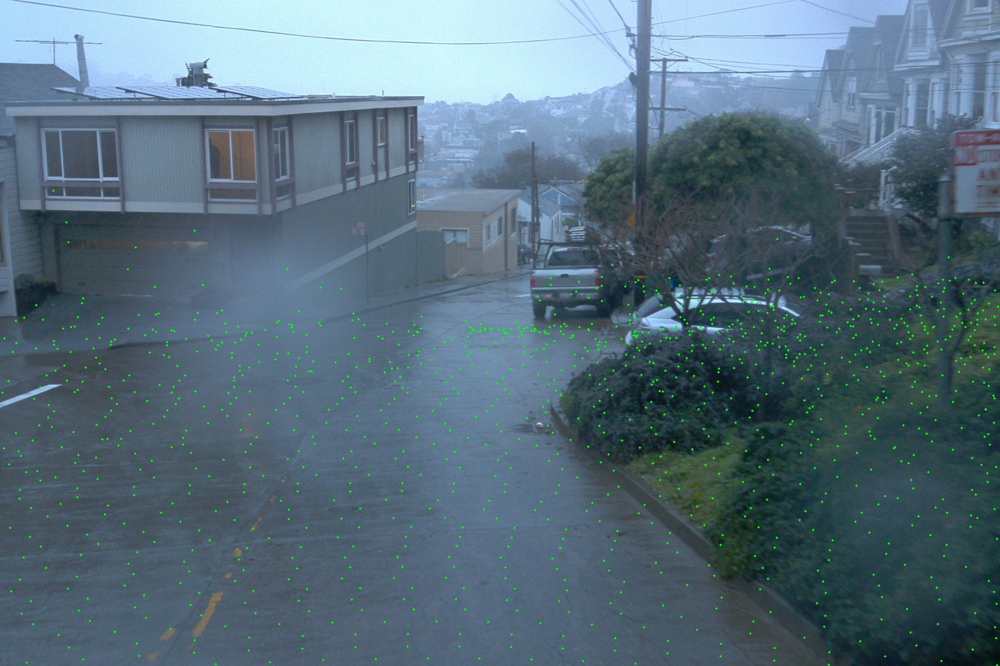

/content/projection_original.jpg | points in front: 4079 | points inside image: 1334


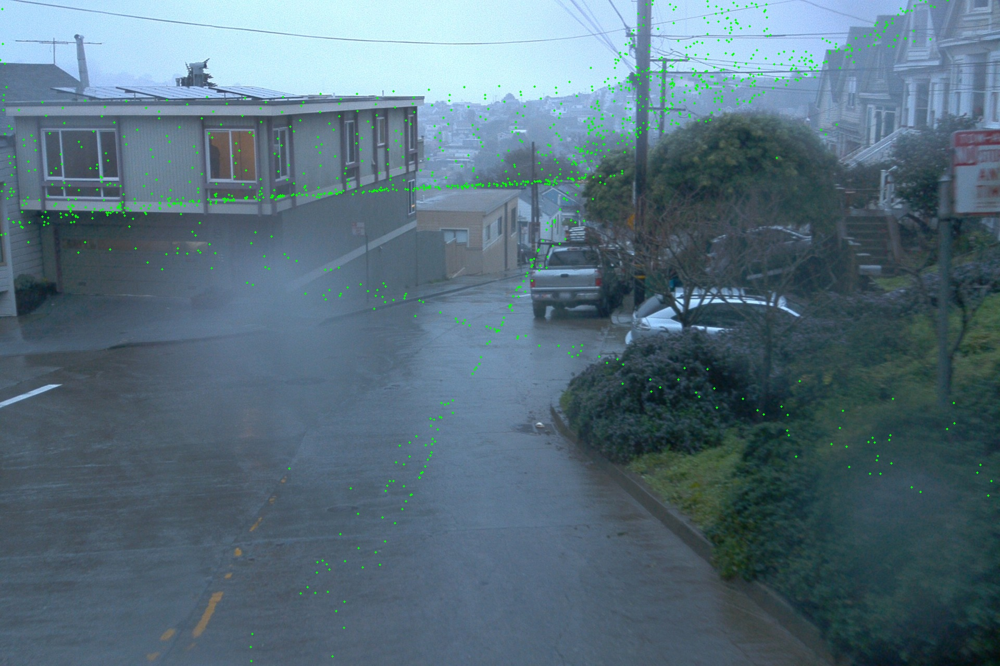

In [67]:
# Tests projection or displays the resulting image overlay.
import numpy as np
import cv2
from IPython.display import display, Image

T_vehicle_camera = np.asarray(calibration["extrinsic"], dtype=float)
T_camera_vehicle = np.linalg.inv(T_vehicle_camera)

pts = points_raw[np.isfinite(points_raw[:, :3]).all(axis=1)]
pts = pts[
    (pts[:, 0] > 1) & (pts[:, 0] < 30) &
    (np.abs(pts[:, 1]) < 12)
]
pts = pts[::20]

def project_with_transform(T, path):
    points_h = np.column_stack([pts[:, :3], np.ones(len(pts))])
    transformed = (T @ points_h.T).T[:, :3]

    # Keep the existing axis conversion for this comparison.
    points_cv = np.column_stack([
        -transformed[:, 1], -transformed[:, 2], transformed[:, 0]
    ])

    front = points_cv[:, 2] > 0.1
    points_cv = points_cv[front]

    uv, _ = cv2.projectPoints(
        points_cv, np.zeros(3), np.zeros(3),
        geometry["K"], geometry["dist"]
    )
    uv = uv.reshape(-1, 2)

    inside = (
        (uv[:, 0] >= 0) & (uv[:, 0] < geometry["image_width"]) &
        (uv[:, 1] >= 0) & (uv[:, 1] < geometry["image_height"])
    )
    uv = uv[inside]

    vis = cv2.cvtColor(np.asarray(frame["image"]), cv2.COLOR_RGB2BGR)
    for u, v in uv:
        cv2.circle(vis, (int(u), int(v)), 2, (0, 255, 0), -1)

    cv2.imwrite(path, vis)
    print(path, "| points in front:", len(points_cv),
          "| points inside image:", len(uv))
    display(Image(filename=path))

project_with_transform(
    T_camera_vehicle, "/content/projection_inverse.jpg"
)
project_with_transform(
    T_vehicle_camera, "/content/projection_original.jpg"
)


In [68]:
# Examines a selected vehicle detection and its geometry.
import numpy as np

d = vehicle_dets[0]
cx, cy, cz, dx, dy, dz, heading = map(float, d["box"])

c, s = np.cos(heading), np.sin(heading)
local_xy = np.array([
    [-dx/2, -dy/2],
    [ dx/2, -dy/2],
    [ dx/2,  dy/2],
    [-dx/2,  dy/2],
])

R = np.array([[c, -s], [s, c]])
xy = local_xy @ R.T + np.array([cx, cy])

# Test both vertical conventions: center-based and ground-based.
corners_center = np.vstack([
    np.column_stack([xy, np.full(4, cz - dz/2)]),
    np.column_stack([xy, np.full(4, cz + dz/2)]),
])

corners_h = np.column_stack([corners_center, np.ones(8)])
camera_xyz = (
    geometry["T_camera_vehicle"] @ corners_h.T
).T[:, :3]

# Current conversion from Waymo camera axes to OpenCV axes.
corners_cv = np.column_stack([
    -camera_xyz[:, 1],
    -camera_xyz[:, 2],
    camera_xyz[:, 0],
])

print("Predicted box:", np.round(d["box"], 3))
print("Camera XYZ corners:\n", np.round(camera_xyz, 3))
print("OpenCV depths:", np.round(corners_cv[:, 2], 3))
print("Corners in front:", int((corners_cv[:, 2] > 0.1).sum()), "/ 8")


Predicted box: [    -17.727      -5.301       0.931       5.171       1.931       2.197       0.005]
Camera XYZ corners:
 [[    -21.813      -6.283      -2.521]
 [    -16.642      -6.239       -2.49]
 [    -16.658      -4.308      -2.456]
 [    -21.829      -4.352      -2.486]
 [    -21.825      -6.322      -0.324]
 [    -16.654      -6.278      -0.294]
 [    -16.671      -4.347      -0.259]
 [    -21.842      -4.391       -0.29]]
OpenCV depths: [    -21.813     -16.642     -16.658     -21.829     -21.825     -16.654     -16.671     -21.842]
Corners in front: 0 / 8


In [69]:
# Prints the trained model configuration.
import numpy as np

print("=== Trained model configuration ===")
print("Top-level keys:", list(cfg.keys()))
print("Model keys:", list(cfg.get("model", {}).keys()))
print("Point cloud range:", cfg.get("model", {}).get("point_cloud_range"))
print("Top-level point cloud range:", cfg.get("point_cloud_range"))

print("\n=== Raw LiDAR point coordinates ===")
print("X percentiles:", np.percentile(points_raw[:, 0], [0, 1, 25, 50, 75, 99, 100]))
print("Y percentiles:", np.percentile(points_raw[:, 1], [0, 1, 25, 50, 75, 99, 100]))
print("Z percentiles:", np.percentile(points_raw[:, 2], [0, 1, 25, 50, 75, 99, 100]))

print("\n=== Predicted box center coordinates ===")
print("X percentiles:", np.percentile(boxes[:, 0], [0, 25, 50, 75, 95, 100]))
print("Y percentiles:", np.percentile(boxes[:, 1], [0, 25, 50, 75, 95, 100]))


=== Trained model configuration ===
Top-level keys: ['name', 'task', 'model', 'voxel', 'data', 'experiment', 'train', 'eval', 'paths']
Model keys: ['type', 'num_classes', 'pfn_out', 'class_names']
Point cloud range: None
Top-level point cloud range: None

=== Raw LiDAR point coordinates ===
X percentiles: [    -72.156     -38.533     -4.0002      1.3349      7.1935      32.777      71.793]
Y percentiles: [    -16.908     -6.8646     -3.8213    -0.90381       8.126      14.994      38.295]
Z percentiles: [   -0.47717    -0.16242     0.83893      1.6758      2.1435      3.1835      4.6277]

=== Predicted box center coordinates ===
X percentiles: [    -22.978       6.869      8.3999      10.399       13.32      33.397]
Y percentiles: [    -7.6292     0.36595      3.8702      7.4322      10.398      16.952]


In [70]:
# Prints voxel configuration details.
print("Voxel config:")
print(cfg["voxel"])

# Use the first high-confidence vehicle detection.
box = np.asarray(boxes[0], dtype=float)
cx, cy, cz, dx, dy, dz, heading = box

print("\nSelected predicted box:", box)
print("Center:", (cx, cy, cz))
print("Dimensions:", (dx, dy, dz))

# Count raw points close to the predicted center.
delta = points_raw[:, :3] - np.array([cx, cy, cz])
distance = np.linalg.norm(delta, axis=1)

print("\nRaw points within 1 m of center:", np.sum(distance < 1.0))
print("Raw points within 2 m of center:", np.sum(distance < 2.0))

# Compare counts in the forward and rear halves of the point cloud.
print("\nRaw points with X > 0:", np.sum(points_raw[:, 0] > 0))
print("Raw points with X < 0:", np.sum(points_raw[:, 0] < 0))


Voxel config:
{'x_range': [-50.0, 50.0], 'y_range': [-50.0, 50.0], 'z_range': [-3.0, 3.0], 'voxel_size': [0.25, 0.25], 'max_pillars': 4096, 'max_points_per_pillar': 20}

Selected predicted box: [    -18.974     -5.5779      1.0217      5.3708      2.0799      2.5991   0.0098676]
Center: (np.float64(-18.974046856164932), np.float64(-5.577946454286575), np.float64(1.0217163562774658))
Dimensions: (np.float64(5.370831342547175), np.float64(2.0798944550037923), np.float64(2.599069883957606))

Raw points within 1 m of center: 0
Raw points within 2 m of center: 123

Raw points with X > 0: 93275
Raw points with X < 0: 71893


In [75]:
# Combines LiDAR prediction and projection operations for a diagnostic test.
import numpy as np
from src.models.pointpillars import predict_lidar
from src.fusion.projection import project_lidar_box

points_raw = frame["points"]
points_model = runner_module._finite_points(points_raw, cfg)

lidar_detections = predict_lidar(
    detector, lidar_model, points_model, cfg
)

# Select the highest-confidence vehicle detection
vehicles = [d for d in lidar_detections if d["label"] == 0]
best = max(vehicles, key=lambda d: d["score"])

print("Best vehicle score:", best["score"])
print("3D box [x, y, z, dx, dy, dz, heading]:", best["box"])

box = np.asarray(best["box"], dtype=float)
print("Box center in vehicle coordinates:", box[:3])

T = geometry["T_camera_vehicle"]
center_h = np.append(box[:3], 1.0)
center_camera = (T @ center_h)[:3]

print("Box center in camera coordinates:", center_camera)
print("Camera depth under current convention:", center_camera[2])

Best vehicle score: 0.392341285943985
3D box [x, y, z, dx, dy, dz, heading]: [np.float64(-17.726940467953682), np.float64(-5.300502724945545), 0.9307680726051331, 5.17133203547688, 1.9312894066834667, 2.196803214131832, 0.005313208165722762]
Box center in vehicle coordinates: [    -17.727     -5.3005     0.93077]
Box center in camera coordinates: [    -19.242     -5.3149       -1.39]
Camera depth under current convention: -1.3899954491006052


In [76]:
# Computes the inverse extrinsic transformation.
T_vehicle_camera = np.asarray(calibration["extrinsic"], dtype=float)
T_camera_vehicle = np.linalg.inv(T_vehicle_camera)

center_h = np.append(box[:3], 1.0)

for name, T in [
    ("inverse extrinsic", T_camera_vehicle),
    ("original extrinsic", T_vehicle_camera),
]:
    p = (T @ center_h)[:3]
    print(f"{name}: {p}")

inverse extrinsic: [    -19.242     -5.3149       -1.39]
original extrinsic: [    -16.199     -5.2495      3.2422]


In [78]:
# Prints image dimensions and calibration extrinsics.
print("Image size (width, height):", frame["image"].size)
print("Calibration extrinsic:")
print(np.asarray(calibration["extrinsic"]))
print("Camera intrinsic matrix:")
print(geometry["K"])
print("Image dimensions:", geometry["image_width"], geometry["image_height"])

Image size (width, height): (1920, 1280)
Calibration extrinsic:
[[    0.99998   0.0031421   0.0057541      1.5391]
 [ -0.0032445     0.99983    0.017878    -0.02403]
 [  -0.005697   -0.017897     0.99982      2.1158]
 [          0           0           0           1]]
Camera intrinsic matrix:
[[     2059.6           0      952.41]
 [          0      2059.6      634.59]
 [          0           0           1]]
Image dimensions: 1920 1280


In [79]:
# Uses OpenCV and NumPy to investigate projection geometry.
import cv2
import numpy as np

center_h = np.append(box[:3], 1.0)
T_ext = np.asarray(calibration["extrinsic"], dtype=float)

for name, T in [
    ("inverse extrinsic", np.linalg.inv(T_ext)),
    ("original extrinsic", T_ext),
]:
    p = (T @ center_h)[:3]

    # Convert vehicle/camera axes to OpenCV camera axes
    p_cv = np.array([-p[1], -p[2], p[0]], dtype=float)

    if p_cv[2] > 0:
        uv, _ = cv2.projectPoints(
            p_cv.reshape(1, 1, 3),
            np.zeros(3), np.zeros(3),
            geometry["K"], geometry["dist"]
        )
        print(name, "depth:", p_cv[2], "pixel:", uv.reshape(2))
    else:
        print(name, "depth:", p_cv[2], "-> behind camera")

inverse extrinsic depth: -19.241802693793307 -> behind camera
original extrinsic depth: -16.198711580018603 -> behind camera


In [82]:
# Constructs or inspects the extrinsic transformation.
import numpy as np

T_ext = np.asarray(calibration["extrinsic"], dtype=float)
points = np.asarray(frame["points"])[:, :3]

# Transform a small sample using both conventions
sample = points[::1000]
sample_h = np.column_stack([sample, np.ones(len(sample))])

for name, T in [
    ("inverse extrinsic", np.linalg.inv(T_ext)),
    ("original extrinsic", T_ext),
]:
    p = (T @ sample_h.T).T[:, :3]
    print(f"\n{name}")
    print("Transformed XYZ percentiles:")
    print(np.round(np.percentile(p, [5, 50, 95], axis=0), 2))


inverse extrinsic
Transformed XYZ percentiles:
[[     -18.74       -6.29       -2.04]
 [       0.06       -0.99       -0.43]
 [      18.52       12.19        0.56]]

original extrinsic
Transformed XYZ percentiles:
[[     -15.65        -6.3        2.02]
 [       3.17       -0.97        3.83]
 [       21.6        12.2        4.76]]


In [83]:
# Runs an OpenCV projection diagnostic.
import cv2
import numpy as np

T_ext = np.asarray(calibration["extrinsic"], dtype=float)
points = np.asarray(frame["points"])[:, :3]
sample = points[::100]

points_h = np.column_stack([sample, np.ones(len(sample))])
p = (T_ext @ points_h.T).T[:, :3]

# Test the assumed OpenCV axis conversion
p_cv = np.column_stack([-p[:, 1], -p[:, 2], p[:, 0]])
front = p_cv[:, 2] > 0.1

print("Sampled points:", len(sample))
print("Points in front:", int(front.sum()))
print("Fraction in front:", round(float(front.mean()), 3))

if front.any():
    uv, _ = cv2.projectPoints(
        p_cv[front], np.zeros(3), np.zeros(3),
        geometry["K"], geometry["dist"]
    )
    uv = uv.reshape(-1, 2)
    inside = (
        (uv[:, 0] >= 0) & (uv[:, 0] < geometry["image_width"]) &
        (uv[:, 1] >= 0) & (uv[:, 1] < geometry["image_height"])
    )
    print("Projected inside image:", int(inside.sum()))

Sampled points: 1652
Points in front: 1035
Fraction in front: 0.627
Projected inside image: 284


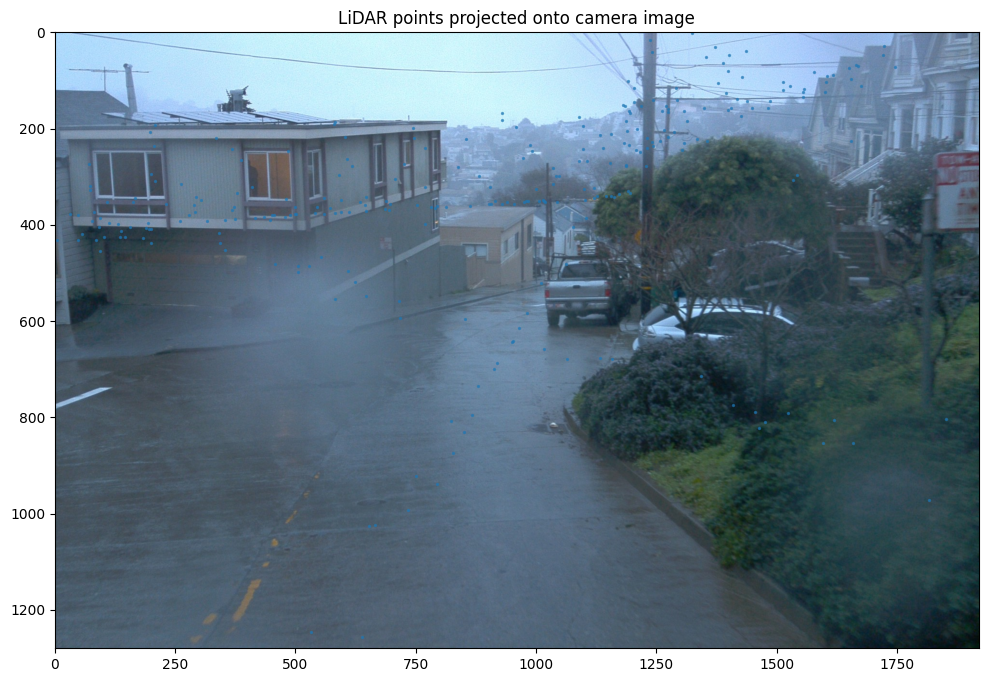

In [84]:
# Plots projected points or coordinates.
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 8))
plt.imshow(frame["image"])

plt.scatter(
    uv[inside, 0],
    uv[inside, 1],
    s=2,
    alpha=0.6
)

plt.xlim(0, geometry["image_width"])
plt.ylim(geometry["image_height"], 0)
plt.title("LiDAR points projected onto camera image")
plt.show()

In [88]:
# Reuse p: points transformed by the inverse extrinsic, in camera-frame coordinates.
# Compare the two possible axis mappings.
mappings = {
    "current [-y, -z, x]": np.column_stack([-p[:, 1], -p[:, 2], p[:, 0]]),
    "alternative [y, -z, x]": np.column_stack([p[:, 1], -p[:, 2], p[:, 0]]),
}

for name, p_cv_test in mappings.items():
    front_test = p_cv_test[:, 2] > 0.1
    proj_test, _ = cv2.projectPoints(
        p_cv_test[front_test],
        np.zeros(3), np.zeros(3),
        geometry["K"], geometry["dist"]
    )
    uv_test = proj_test.reshape(-1, 2)
    inside_test = (
        (uv_test[:, 0] >= 0) & (uv_test[:, 0] < geometry["image_width"]) &
        (uv_test[:, 1] >= 0) & (uv_test[:, 1] < geometry["image_height"])
    )
    print(name, "| in front:", int(front_test.sum()),
          "| inside image:", int(inside_test.sum()))

current [-y, -z, x] | in front: 76898 | inside image: 24701
alternative [y, -z, x] | in front: 76898 | inside image: 24696


In [89]:
# Prints camera and LiDAR timestamps.
print("Camera timestamp:", frame["camera_timestamp"])
print("LiDAR return 1 timestamp:", frame["lidar1_timestamp"])
print("LiDAR return 2 timestamp:", frame["lidar2_timestamp"])

if all(frame[k] is not None for k in [
    "camera_timestamp", "lidar1_timestamp", "lidar2_timestamp"
]):
    print("Camera - LiDAR 1:", frame["camera_timestamp"] - frame["lidar1_timestamp"])
    print("Camera - LiDAR 2:", frame["camera_timestamp"] - frame["lidar2_timestamp"])

Camera timestamp: 1550083467346370
LiDAR return 1 timestamp: 1550083467346370
LiDAR return 2 timestamp: 1550083467346370
Camera - LiDAR 1: 0
Camera - LiDAR 2: 0


In [90]:
# Reports projected pixel-coordinate percentiles.
print("Projected pixel percentiles [u, v]:")
print(np.round(np.percentile(uv1[inside], [0, 10, 25, 50, 75, 90, 100], axis=0), 1))

Projected pixel percentiles [u, v]:
[[        0.1       276.9]
 [      201.3       567.4]
 [      498.7       631.7]
 [     1013.3       731.3]
 [     1464.1       931.9]
 [     1738.6      1121.9]
 [     1919.9      1279.9]]


In [91]:
# Counts detection properties with Counter.
from collections import Counter
import numpy as np

print("Total detections:", len(lidar_detections))

print("\nDetection counts by class:")
print(Counter(d["label"] for d in lidar_detections))

print("\nVehicle detection centers [x, y, z] and scores:")
for d in sorted(
    (d for d in lidar_detections if d["label"] == 0),
    key=lambda d: d["score"],
    reverse=True
)[:15]:
    b = np.asarray(d["box"], dtype=float)
    print(
        f"score={d['score']:.3f}, "
        f"center=({b[0]:.2f}, {b[1]:.2f}, {b[2]:.2f})"
    )

Total detections: 360

Detection counts by class:
Counter({1: 328, 0: 32})

Vehicle detection centers [x, y, z] and scores:
score=0.392, center=(-17.73, -5.30, 0.93)
score=0.389, center=(-8.76, 0.28, 0.87)
score=0.365, center=(-18.05, -5.67, 1.05)
score=0.335, center=(-18.15, -5.29, 0.96)
score=0.307, center=(-18.49, -5.61, 1.03)
score=0.297, center=(-17.65, -5.68, 1.06)
score=0.280, center=(-9.28, 0.26, 0.86)
score=0.274, center=(-8.73, 0.82, 0.91)
score=0.270, center=(-18.57, -5.22, 0.97)
score=0.269, center=(-8.76, -0.23, 0.85)
score=0.259, center=(20.27, -3.82, 0.90)
score=0.244, center=(18.78, -3.35, 0.93)
score=0.242, center=(-9.29, -0.24, 0.84)
score=0.237, center=(-2.14, -3.25, 0.99)
score=0.236, center=(19.78, -3.35, 0.85)


In [92]:
# Computes or checks the inverse camera transformation.
import numpy as np

T_camera_vehicle = np.linalg.inv(
    np.asarray(calibration["extrinsic"], dtype=float)
)

print("Vehicle detections and camera-frame depth:")
for d in sorted(
    (d for d in lidar_detections if d["label"] == 0),
    key=lambda d: d["score"],
    reverse=True
)[:15]:
    b = np.asarray(d["box"], dtype=float)
    center_h = np.append(b[:3], 1.0)
    center_camera = (T_camera_vehicle @ center_h)[:3]

    # Under the current Waymo-to-OpenCV conversion, depth is camera X.
    depth = center_camera[0]

    print(
        f"score={d['score']:.3f}, "
        f"vehicle_x={b[0]:.2f}, "
        f"camera_depth={depth:.2f} m, "
        f"{'IN FRONT' if depth > 0.1 else 'BEHIND'}"
    )

Vehicle detections and camera-frame depth:
score=0.392, vehicle_x=-17.73, camera_depth=-19.24 m, BEHIND
score=0.389, vehicle_x=-8.76, camera_depth=-10.29 m, BEHIND
score=0.365, vehicle_x=-18.05, camera_depth=-19.57 m, BEHIND
score=0.335, vehicle_x=-18.15, camera_depth=-19.67 m, BEHIND
score=0.307, vehicle_x=-18.49, camera_depth=-20.00 m, BEHIND
score=0.297, vehicle_x=-17.65, camera_depth=-19.17 m, BEHIND
score=0.280, vehicle_x=-9.28, camera_depth=-10.82 m, BEHIND
score=0.274, vehicle_x=-8.73, camera_depth=-10.26 m, BEHIND
score=0.270, vehicle_x=-18.57, camera_depth=-20.08 m, BEHIND
score=0.269, vehicle_x=-8.76, camera_depth=-10.29 m, BEHIND
score=0.259, vehicle_x=20.27, camera_depth=18.75 m, IN FRONT
score=0.244, vehicle_x=18.78, camera_depth=17.26 m, IN FRONT
score=0.242, vehicle_x=-9.29, camera_depth=-10.82 m, BEHIND
score=0.237, vehicle_x=-2.14, camera_depth=-3.66 m, BEHIND
score=0.236, vehicle_x=19.78, camera_depth=18.25 m, IN FRONT


In [102]:
# Inspects the LiDAR point-cloud array.
import numpy as np

points = np.asarray(frame["points"])
print("Point cloud X range:", points[:, 0].min(), points[:, 0].max())
print("Point cloud Y range:", points[:, 1].min(), points[:, 1].max())

for label, name in [(0, "vehicle"), (1, "pedestrian")]:
    detections = [d for d in lidar_detections if d["label"] == label]
    front = [d for d in detections if d["box"][0] > 0]
    behind = [d for d in detections if d["box"][0] <= 0]
    print(f"\n{name}: {len(detections)} total")
    print(f"  X > 0: {len(front)}")
    print(f"  X <= 0: {len(behind)}")

Point cloud X range: -72.15613 71.793335
Point cloud Y range: -16.908203 38.29492

vehicle: 32 total
  X > 0: 11
  X <= 0: 21

pedestrian: 328 total
  X > 0: 328
  X <= 0: 0


In [103]:
# Selects and sorts vehicle detections in front of the camera.
vehicles_front = sorted(
    (
        d for d in lidar_detections
        if d["label"] == 0 and d["box"][0] > 0
    ),
    key=lambda d: d["score"],
    reverse=True,
)

for d in vehicles_front:
    b = d["box"]
    print(
        f"score={d['score']:.3f}, "
        f"center=({b[0]:.2f}, {b[1]:.2f}, {b[2]:.2f}), "
        f"size=({b[3]:.2f}, {b[4]:.2f}, {b[5]:.2f})"
    )

score=0.259, center=(20.27, -3.82, 0.90), size=(3.59, 1.60, 1.92)
score=0.244, center=(18.78, -3.35, 0.93), size=(3.36, 1.61, 1.96)
score=0.236, center=(19.78, -3.35, 0.85), size=(3.57, 1.65, 1.87)
score=0.224, center=(20.28, -3.35, 0.84), size=(3.65, 1.67, 1.85)
score=0.221, center=(19.77, -3.81, 0.91), size=(3.14, 1.50, 1.88)
score=0.218, center=(19.29, -3.34, 0.90), size=(3.34, 1.59, 1.91)
score=0.206, center=(28.43, 7.99, 0.66), size=(6.66, 2.46, 1.62)
score=0.206, center=(28.44, 7.49, 0.67), size=(6.54, 2.44, 1.65)
score=0.205, center=(30.46, -0.51, 0.75), size=(6.31, 2.37, 1.76)
score=0.204, center=(19.92, 11.98, 0.66), size=(6.02, 2.32, 1.61)
score=0.203, center=(33.40, 16.95, 0.64), size=(6.18, 2.39, 1.71)


In [109]:
# Runs geometric projection and association for a frame.
result = runner_module.run_fusion_frame(
    frame_idx=0,
    detector=detector,
    lidar_model=lidar_model,
    cfg=cfg,
    camera_model=camera_model,
    context_dir=context_dir,
    save_visualization=True,
)

print(result)

{'frame_idx': 0, 'num_points_raw': 165170, 'num_points_model': 165170, 'num_lidar_detections': 360, 'num_camera_detections': 3, 'num_camera_candidates': 3, 'num_projected_boxes': 194, 'num_matches': 1, 'mean_matched_iou': 0.5682364458913775, 'lidar_inference_seconds': 2.9630657880006765, 'camera_inference_seconds': 0.21582878499975777, 'total_seconds': 4.341475428000194, 'csv_path': '/content/drive/MyDrive/Colab Notebooks/3DPerception/project/experiments/experiment_1_results/experiment_1_detections.csv', 'visualization_path': '/content/drive/MyDrive/Colab Notebooks/3DPerception/project/experiments/experiment_1_results/frame_000_fusion.jpg', 'iou_matrix': array([[          0,           0,           0],
       [          0,           0,           0],
       [          0,           0,           0],
       ...,
       [          0,           0,           0],
       [          0,           0,           0],
       [          0,           0,           0]]), 'matches': [(15, 2, 0.5682364458913

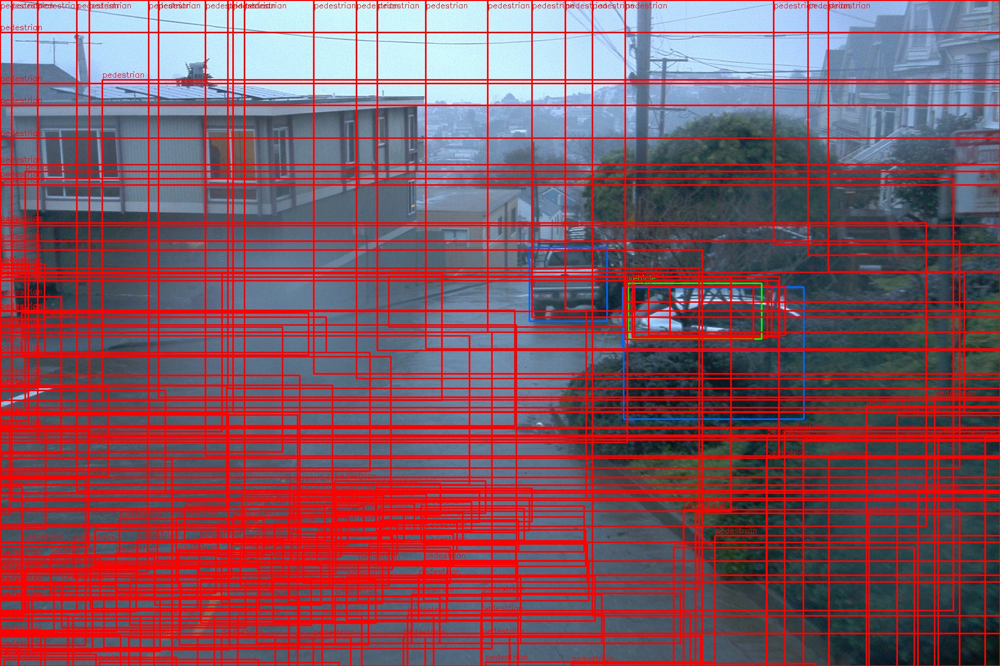

In [110]:
# Displays the output visualization from the test.
from PIL import Image
from IPython.display import display

display(Image.open(result["visualization_path"]))

In [ ]:
# Uses NumPy and Counter for additional detection analysis
import numpy as np
from collections import Counter

print("Total detections:", len(lidar_detections))
print("Class counts:", Counter(int(d["label"]) for d in lidar_detections))

boxes = np.array([d["box"] for d in lidar_detections], dtype=float)
scores = np.array([d["score"] for d in lidar_detections], dtype=float)

print("\nBox format: [cx, cy, cz, dx, dy, dz, heading]")
for i in np.argsort(scores)[::-1][:15]:
    print(
        f"label={lidar_detections[i]['label']}, "
        f"score={scores[i]:.3f}, "
        f"box={np.round(boxes[i], 2)}"
    )

print("\nDimension statistics [dx, dy, dz]:")
print("Minimum:", np.round(np.nanmin(boxes[:, 3:6], axis=0), 2))
print("Median: ", np.round(np.nanmedian(boxes[:, 3:6], axis=0), 2))
print("Maximum:", np.round(np.nanmax(boxes[:, 3:6], axis=0), 2))

Total detections: 360
Class counts: Counter({1: 328, 0: 32})

Box format: [cx, cy, cz, dx, dy, dz, heading]
label=0, score=0.392, box=[     -17.73        -5.3        0.93        5.17        1.93         2.2        0.01]
label=0, score=0.389, box=[      -8.76        0.28        0.87        4.85        2.22        1.83        0.01]
label=0, score=0.365, box=[     -18.05       -5.67        1.05        5.63        2.03        2.52        0.02]
label=0, score=0.335, box=[     -18.15       -5.29        0.96        5.27        1.96        2.24        0.01]
label=1, score=0.325, box=[       7.43        0.41        0.91        1.03        0.96         1.7       -1.55]
label=1, score=0.316, box=[       7.41       -0.09        0.91        1.03        0.95        1.68       -1.54]
label=1, score=0.315, box=[       5.87        5.39        0.78        1.09        1.01        1.82       -1.57]
label=1, score=0.315, box=[       6.92         0.4        0.91           1        0.96         1.7       -1.

In [120]:
# Uses pandas and NumPy to inspect result data.
import pandas as pd
import numpy as np

df = pd.read_csv(result["csv_path"])
df = df[df["frame_idx"] == result["frame_idx"]].copy()

def parse_box(value):
    if pd.isna(value) or value in ("None", "null", ""):
        return None
    import ast
    box = ast.literal_eval(value) if isinstance(value, str) else value
    return box if isinstance(box, (list, tuple)) else None

df["box2d"] = df["projected_box_2d"].apply(parse_box)
valid = df[df["box2d"].apply(lambda b: b is not None)].copy()

sizes = np.array([
    [b[2] - b[0], b[3] - b[1]]
    for b in valid["box2d"]
    if len(b) == 4
])

print("Frame:", result["frame_idx"])
print("CSV rows for frame:", len(df))
print("Valid projected boxes:", len(sizes))

if len(sizes):
    print("Width percentiles:", np.percentile(sizes[:, 0], [0, 25, 50, 75, 95, 100]).round(1))
    print("Height percentiles:", np.percentile(sizes[:, 1], [0, 25, 50, 75, 95, 100]).round(1))
    print("Boxes wider than half the image:", int((sizes[:, 0] > geometry["image_width"] / 2).sum()))
    print("Boxes taller than half the image:", int((sizes[:, 1] > geometry["image_height"] / 2).sum()))

Frame: 0
CSV rows for frame: 2520
Valid projected boxes: 1358
Width percentiles: [        0.6       261.8       347.1       719.6        1920        1920]
Height percentiles: [        4.6        68.9        98.6       443.2         943      1183.9]
Boxes wider than half the image: 287
Boxes taller than half the image: 182


In [121]:
# Uses inspect to examine the projection implementation.
import inspect
import src.fusion.projection as projection_module

original_project = projection_module.project_lidar_box

def project_lidar_box_checked(
    box, points_vehicle, T_camera_vehicle, K, dist,
    image_width, image_height, min_points=10
):
    # Preserve the existing function's geometry and filtering.
    x, y, cz, sx, sy, dz, heading = map(float, box)

    if sx <= 0 or sy <= 0 or dz <= 0:
        return None

    c, s = np.cos(heading), np.sin(heading)
    local_corners = np.array([
        [-sx/2, -sy/2], [sx/2, -sy/2],
        [sx/2, sy/2], [-sx/2, sy/2]
    ])
    rotation = np.array([[c, -s], [s, c]])
    xy = local_corners @ rotation.T + np.array([x, y])

    corners_vehicle = np.vstack([
        np.column_stack([xy, np.full(4, cz - dz/2)]),
        np.column_stack([xy, np.full(4, cz + dz/2)])
    ])
    corners_h = np.column_stack([corners_vehicle, np.ones(8)])
    corners_camera = (T_camera_vehicle @ corners_h.T).T[:, :3]
    depths = corners_camera[:, 0]  # OpenCV forward depth

    # Reject boxes intersecting the near-camera plane.
    if np.any(depths <= 0.1):
        return None

    return original_project(
        box, points_vehicle, T_camera_vehicle, K, dist,
        image_width, image_height, min_points
    )

projection_module.project_lidar_box = project_lidar_box_checked
runner_module.project_lidar_box = project_lidar_box_checked

print("Patched projection function in the current session.")

Patched projection function in the current session.


In [122]:
# Executes another single-frame fusion test.
test_result = runner_module.run_fusion_frame(
    frame_idx=0,
    detector=detector,
    lidar_model=lidar_model,
    cfg=cfg,
    camera_model=camera_model,
    context_dir=context_dir,
    output_dir="/content/experiment_1_projection_test",
    save_visualization=True,
)

print({
    key: test_result[key]
    for key in (
        "num_lidar_detections",
        "num_camera_detections",
        "num_projected_boxes",
        "num_matches",
        "mean_matched_iou",
        "visualization_path",
    )
})

{'num_lidar_detections': 360, 'num_camera_detections': 3, 'num_projected_boxes': 194, 'num_matches': 1, 'mean_matched_iou': 0.5682364458913775, 'visualization_path': '/content/experiment_1_projection_test/frame_000_fusion.jpg'}


In [123]:
# Restores the original projection function.
import src.fusion.projection as projection_module

projection_module.project_lidar_box = original_project
runner_module.project_lidar_box = original_project

print("Original projection restored in this session.")
print("Camera transform:\n", geometry["T_camera_vehicle"])
print("Camera intrinsic matrix:\n", geometry["K"])
print("Example LiDAR box:", lidar_detections[0]["box"])

Original projection restored in this session.
Camera transform:
 [[    0.99998  -0.0032445   -0.005697     -1.5271]
 [  0.0031421     0.99983   -0.017897    0.057055]
 [  0.0057541    0.017878     0.99982     -2.1238]
 [          0           0           0           1]]
Camera intrinsic matrix:
 [[     2059.6           0      952.41]
 [          0      2059.6      634.59]
 [          0           0           1]]
Example LiDAR box: [np.float64(-18.974046856164932), np.float64(-5.577946454286575), 1.0217163562774658, 5.370831342547175, 2.0798944550037923, 2.599069883957606, 0.009867600155684001]


In [124]:
# Inspects the projection function and LiDAR prediction behavior.
import inspect
from src.models.pointpillars import predict_lidar
from src.fusion import projection

print("=== predict_lidar wrapper ===")
print(inspect.getsource(predict_lidar))

print("\n=== projection module path ===")
print(inspect.getfile(projection))

print("\n=== existing LiDAR detections ===")
for d in lidar_detections[:5]:
    print({
        "label": d["label"],
        "score": round(float(d["score"]), 3),
        "box": np.round(d["box"], 3).tolist(),
    })

=== predict_lidar wrapper ===
def predict_lidar(detector, model, points, cfg):
    """Predict boxes from a single (N, 4) XYZI point cloud."""
    import numpy as np

    points = np.asarray(points, dtype=np.float32)
    if points.ndim != 2 or points.shape[1] < 4:
        raise ValueError(f"Expected points shaped (N, >=4), got {points.shape}")

    return detector.predict(model, points[:, :4], cfg)


=== projection module path ===
/content/src/fusion/projection.py

=== existing LiDAR detections ===
{'label': 0, 'score': 0.222, 'box': [-18.974, -5.578, 1.022, 5.371, 2.08, 2.599, 0.01]}
{'label': 0, 'score': 0.307, 'box': [-18.487, -5.609, 1.032, 5.229, 1.987, 2.58, 0.025]}
{'label': 0, 'score': 0.365, 'box': [-18.054, -5.67, 1.046, 5.627, 2.025, 2.523, 0.022]}
{'label': 0, 'score': 0.297, 'box': [-17.652, -5.678, 1.06, 5.485, 1.975, 2.446, 0.029]}
{'label': 0, 'score': 0.232, 'box': [-19.028, -5.148, 0.973, 5.257, 2.043, 2.371, 0.015]}


## Box geometry and projection failure analysis

In [127]:
# Compares camera and vehicle origins using the extrinsic transformation.
import numpy as np

T_vehicle_camera = np.asarray(calibration["extrinsic"], dtype=float)
T_camera_vehicle = geometry["T_camera_vehicle"]

camera_origin_vehicle = T_vehicle_camera @ np.array([0., 0., 0., 1.])
vehicle_origin_camera = T_camera_vehicle @ np.array([0., 0., 0., 1.])

print("Camera origin expressed in vehicle coordinates:",
      camera_origin_vehicle[:3])
print("Vehicle origin expressed in camera coordinates:",
      vehicle_origin_camera[:3])
print("Inverse consistency error:",
      np.max(np.abs(T_camera_vehicle @ T_vehicle_camera - np.eye(4))))

Camera origin expressed in vehicle coordinates: [     1.5391    -0.02403      2.1158]
Vehicle origin expressed in camera coordinates: [    -1.5271    0.057055     -2.1238]
Inverse consistency error: 1.1102230246251565e-16


In [128]:
# Reads the fusion CSV and inspects projected detections, including large projected boxes.
import ast
import numpy as np
import pandas as pd

df = pd.read_csv(result["csv_path"])
latest = (
    df[df["frame_idx"] == result["frame_idx"]]
    .tail(result["num_lidar_detections"])
    .copy()
)

T = geometry["T_camera_vehicle"]
records = []

for row in latest.itertuples():
    if pd.isna(row.projected_box_2d):
        continue

    box2d = ast.literal_eval(row.projected_box_2d)
    box3d = ast.literal_eval(row.lidar_box_3d)

    if not isinstance(box2d, (list, tuple)) or len(box2d) != 4:
        continue

    cx, cy, cz, dx, dy, dz, heading = map(float, box3d)
    camera_center = T @ np.array([cx, cy, cz, 1.0])
    depth = float(camera_center[0])

    x1, y1, x2, y2 = map(float, box2d)
    width, height = x2 - x1, y2 - y1

    records.append({
        "lidar_index": row.lidar_index,
        "class": row.lidar_class,
        "score": round(float(row.lidar_score), 3),
        "center_vehicle": np.round([cx, cy, cz], 2).tolist(),
        "dimensions": np.round([dx, dy, dz], 2).tolist(),
        "camera_depth_m": round(depth, 2),
        "box_2d_wh": [round(width, 1), round(height, 1)],
        "box_2d_xyxy": np.round([x1, y1, x2, y2], 1).tolist(),
    })

records.sort(
    key=lambda r: r["box_2d_wh"][0] * r["box_2d_wh"][1],
    reverse=True,
)

print("Rows examined:", len(latest))
print("Valid projected boxes:", len(records))
print("\nLargest 10 projected boxes:")
for record in records[:10]:
    print(record)

Rows examined: 360
Valid projected boxes: 194

Largest 10 projected boxes:
{'lidar_index': 217, 'class': 'pedestrian', 'score': 0.293, 'center_vehicle': [6.38, 5.39, 0.78], 'dimensions': [1.13, 1.01, 1.83], 'camera_depth_m': 4.83, 'box_2d_wh': [1920.0, 1155.3], 'box_2d_xyxy': [0.0, 62.3, 1920.0, 1217.6]}
{'lidar_index': 216, 'class': 'pedestrian', 'score': 0.315, 'center_vehicle': [5.87, 5.39, 0.78], 'dimensions': [1.09, 1.01, 1.82], 'camera_depth_m': 4.32, 'box_2d_wh': [1920.0, 1118.8], 'box_2d_xyxy': [0.0, 0.0, 1920.0, 1118.8]}
{'lidar_index': 228, 'class': 'pedestrian', 'score': 0.274, 'center_vehicle': [6.39, 5.89, 0.76], 'dimensions': [1.11, 1.01, 1.82], 'camera_depth_m': 4.84, 'box_2d_wh': [1920.0, 1106.0], 'box_2d_xyxy': [0.0, 0.0, 1920.0, 1106.0]}
{'lidar_index': 240, 'class': 'pedestrian', 'score': 0.251, 'center_vehicle': [6.9, 6.4, 0.78], 'dimensions': [1.09, 1.01, 1.8], 'camera_depth_m': 5.34, 'box_2d_wh': [1920.0, 1078.2], 'box_2d_xyxy': [0.0, 0.0, 1920.0, 1078.2]}
{'lidar

In [130]:
# Computes the 3D corners of a selected box in vehicle coordinates.
import numpy as np

box = [6.38, 5.39, 0.78, 1.13, 1.01, 1.83, 0.0]
cx, cy, cz, dx, dy, dz, heading = map(float, box)
c, s = np.cos(heading), np.sin(heading)

local_xy = np.array([
    [-dx/2, -dy/2],
    [ dx/2, -dy/2],
    [ dx/2,  dy/2],
    [-dx/2,  dy/2],
])

rotation = np.array([[c, -s], [s, c]])
xy_vehicle = local_xy @ rotation.T + np.array([cx, cy])

corners_vehicle = np.vstack([
    np.column_stack([xy_vehicle, np.full(4, cz - dz/2)]),
    np.column_stack([xy_vehicle, np.full(4, cz + dz/2)]),
])

corners_h = np.column_stack([corners_vehicle, np.ones(8)])
corners_camera = (geometry["T_camera_vehicle"] @ corners_h.T).T[:, :3]

# The projection code assumes vehicle x becomes camera depth,
# vehicle y becomes negative camera horizontal, and vehicle z
# becomes negative camera vertical.
corners_cv = np.column_stack([
    -corners_camera[:, 1],
    -corners_camera[:, 2],
    corners_camera[:, 0],
])

print("Vehicle-frame corners:\n", np.round(corners_vehicle, 3))
print("\nCamera-frame coordinates:\n", np.round(corners_camera, 3))
print("\nOpenCV-frame coordinates (x, y, depth):\n", np.round(corners_cv, 3))

Vehicle-frame corners:
 [[      5.815       4.885      -0.135]
 [      6.945       4.885      -0.135]
 [      6.945       5.895      -0.135]
 [      5.815       5.895      -0.135]
 [      5.815       4.885       1.695]
 [      6.945       4.885       1.695]
 [      6.945       5.895       1.695]
 [      5.815       5.895       1.695]]

Camera-frame coordinates:
 [[      4.273       4.962      -2.138]
 [      5.403       4.965      -2.132]
 [      5.399       5.975      -2.113]
 [      4.269       5.972       -2.12]
 [      4.262       4.929      -0.308]
 [      5.392       4.933      -0.302]
 [      5.389       5.943      -0.284]
 [      4.259       5.939       -0.29]]

OpenCV-frame coordinates (x, y, depth):
 [[     -4.962       2.138       4.273]
 [     -4.965       2.132       5.403]
 [     -5.975       2.113       5.399]
 [     -5.972        2.12       4.269]
 [     -4.929       0.308       4.262]
 [     -4.933       0.302       5.392]
 [     -5.943       0.284       5.389]
 [     

In [131]:
# Projects the corners of a specific detection and examines its camera depths.
import ast
import cv2
import numpy as np

# Retrieve the exact detection from the latest frame-0 run.
row = latest.loc[latest["lidar_index"] == 217].iloc[-1]
box = np.asarray(ast.literal_eval(row["lidar_box_3d"]), dtype=float)

cx, cy, cz, dx, dy, dz, heading = box
c, s = np.cos(heading), np.sin(heading)

local_corners = np.array([
    [-dx/2, -dy/2],
    [ dx/2, -dy/2],
    [ dx/2,  dy/2],
    [-dx/2,  dy/2],
], dtype=float)

rotation = np.array([[c, -s], [s, c]])
xy = local_corners @ rotation.T + np.array([cx, cy])

corners_vehicle = np.vstack([
    np.column_stack([xy, np.full(4, cz - dz/2)]),
    np.column_stack([xy, np.full(4, cz + dz/2)]),
])
corners_h = np.column_stack([corners_vehicle, np.ones(8)])

corners_camera = (
    geometry["T_camera_vehicle"] @ corners_h.T
).T[:, :3]

# Match the camera-axis conversion in src/fusion/projection.py.
corners_cv = np.column_stack([
    -corners_camera[:, 1],
    -corners_camera[:, 2],
    corners_camera[:, 0],
])

front = corners_cv[:, 2] > 0.1
raw_uv, _ = cv2.projectPoints(
    corners_cv[front],
    np.zeros(3),
    np.zeros(3),
    geometry["K"],
    geometry["dist"],
)
raw_uv = raw_uv.reshape(-1, 2)

print("Exact 3D detection:", box)
print("Camera depths:", np.round(corners_cv[:, 2], 3))
print("Raw projected pixels (before clipping):\n", np.round(raw_uv, 1))
print("Raw pixel bounds:", np.round([
    raw_uv[:, 0].min(), raw_uv[:, 1].min(),
    raw_uv[:, 0].max(), raw_uv[:, 1].max()
], 1))
print("Stored projected box:", row["projected_box_2d"])
print("Image dimensions:",
      geometry["image_width"], "x", geometry["image_height"])

Exact 3D detection: [     6.3798       5.393     0.78418      1.1251      1.0103      1.8348     -1.5886]
Camera depths: [      4.339       4.322       5.333       5.349       4.328       4.312       5.322       5.339]
Raw projected pixels (before clipping):
 [[     2468.9       104.5]
 [        363       891.8]
 [     -357.8        1205]
 [      114.9       928.7]
 [     1513.6       608.5]
 [     -172.6       704.4]
 [     -534.4       725.3]
 [     -209.7       688.3]]
Raw pixel bounds: [     -534.4       104.5      2468.9        1205]
Stored projected box: [0.0, 62.33044873062613, 1920.0, 1217.6497792354821]
Image dimensions: 1920 x 1280


In [132]:
# Compares projected bounds under alternative box-heading conventions.
import cv2
import numpy as np

box = np.asarray(box, dtype=float)  # Exact detection 217 from the previous cell
cx, cy, cz, dx, dy, dz, heading = box

def project_variant(dx, dy, heading):
    c, s = np.cos(heading), np.sin(heading)
    local_xy = np.array([
        [-dx/2, -dy/2],
        [ dx/2, -dy/2],
        [ dx/2,  dy/2],
        [-dx/2,  dy/2],
    ])
    rotation = np.array([[c, -s], [s, c]])
    xy = local_xy @ rotation.T + [cx, cy]
    corners = np.vstack([
        np.column_stack([xy, np.full(4, cz-dz/2)]),
        np.column_stack([xy, np.full(4, cz+dz/2)]),
    ])
    corners_h = np.column_stack([corners, np.ones(8)])
    cam = (geometry["T_camera_vehicle"] @ corners_h.T).T[:, :3]
    cv = np.column_stack([-cam[:, 1], -cam[:, 2], cam[:, 0]])

    if np.any(cv[:, 2] <= 0.1):
        return {"error": "corner behind camera"}

    uv, _ = cv2.projectPoints(
        cv, np.zeros(3), np.zeros(3),
        geometry["K"], geometry["dist"]
    )
    uv = uv.reshape(-1, 2)
    return {
        "raw_bounds_xyxy": np.round([
            uv[:, 0].min(), uv[:, 1].min(),
            uv[:, 0].max(), uv[:, 1].max()
        ], 1).tolist(),
        "raw_width_height": np.round([
            uv[:, 0].max()-uv[:, 0].min(),
            uv[:, 1].max()-uv[:, 1].min()
        ], 1).tolist(),
    }

variants = {
    "original": (dx, dy, heading),
    "heading_reversed": (dx, dy, -heading),
    "dimensions_swapped": (dy, dx, heading),
    "both_changed": (dy, dx, -heading),
}

for name, params in variants.items():
    print(name, "->", project_variant(*params))

original -> {'raw_bounds_xyxy': [-534.4, 104.5, 2468.9, 1205.0], 'raw_width_height': [3003.3, 1100.4]}
heading_reversed -> {'raw_bounds_xyxy': [-534.5, 89.4, 2507.0, 1203.4], 'raw_width_height': [3041.5, 1114.0]}
dimensions_swapped -> {'raw_bounds_xyxy': [-534.4, 63.3, 2570.3, 1199.8], 'raw_width_height': [3104.6, 1136.5]}
both_changed -> {'raw_bounds_xyxy': [-534.2, 52.7, 2594.4, 1197.7], 'raw_width_height': [3128.6, 1145.0]}


In [133]:
# Compares projections with and without calibration distortion.
import cv2
import numpy as np

# Reuse corners_cv from the exact detection 217 diagnostic.
K = geometry["K"]
dist = geometry["dist"]
zero_dist = np.zeros_like(dist)

for name, distortion in [
    ("With calibration distortion", dist),
    ("Without distortion", zero_dist),
]:
    uv, _ = cv2.projectPoints(
        corners_cv,
        np.zeros(3),
        np.zeros(3),
        K,
        distortion,
    )
    uv = uv.reshape(-1, 2)

    print(f"\n{name}")
    print("Projected corners:\n", np.round(uv, 1))
    print("Bounds [x1, y1, x2, y2]:", np.round([
        uv[:, 0].min(),
        uv[:, 1].min(),
        uv[:, 0].max(),
        uv[:, 1].max(),
    ], 1))


With calibration distortion
Projected corners:
 [[     2468.9       104.5]
 [        363       891.8]
 [     -357.8        1205]
 [      114.9       928.7]
 [     1513.6       608.5]
 [     -172.6       704.4]
 [     -534.4       725.3]
 [     -209.7       688.3]]
Bounds [x1, y1, x2, y2]: [     -534.4       104.5      2468.9        1205]

Without distortion
Projected corners:
 [[    -1915.4      1639.3]
 [    -1390.3      1652.7]
 [     -940.8      1457.7]
 [    -1368.1      1447.4]
 [    -1906.7       768.8]
 [    -1380.3         779]
 [     -931.8       749.4]
 [      -1360       741.3]]
Bounds [x1, y1, x2, y2]: [    -1915.4       741.3      -931.8      1652.7]


In [135]:
# Checks camera-image dimensions, image mode and prediction interface.
import inspect
import numpy as np

from src.models.camera_detector import predict_camera
from src.data.waymo_fusion_data import load_fusion_frame

frame = load_fusion_frame(context_dir, 0)
image = frame["image"]

print("Image type:", type(image))
print("Image size (width, height):", image.size)
print("Image mode:", image.mode)
print("Image array shape (height, width, channels):",
      np.asarray(image).shape)
print("Calibration size (width, height):",
      geometry["image_width"], geometry["image_height"])

print("\n=== predict_camera implementation ===")
print(inspect.getsource(predict_camera))

Image type: <class 'PIL.Image.Image'>
Image size (width, height): (1920, 1280)
Image mode: RGB
Image array shape (height, width, channels): (1280, 1920, 3)
Calibration size (width, height): 1920 1280

=== predict_camera implementation ===
def predict_camera(model, image, confidence=0.25):
    """Return camera boxes, scores, class IDs, and class names."""
    result = model.predict(
        source=image,
        conf=confidence,
        verbose=False,
    )[0]

    if result.boxes is None or len(result.boxes) == 0:
        return {
            "boxes": [],
            "scores": [],
            "labels": [],
            "names": result.names,
        }

    return {
        "boxes": result.boxes.xyxy.cpu().numpy(),
        "scores": result.boxes.conf.cpu().numpy(),
        "labels": result.boxes.cls.cpu().numpy().astype(int),
        "names": result.names,
    }



In [136]:
# Transforms the vehicle origin into camera-aligned and OpenCV coordinates.
import numpy as np

T = geometry["T_camera_vehicle"]
K = geometry["K"]

# Vehicle origin expressed in the current OpenCV camera frame.
origin_vehicle = np.array([0., 0., 0., 1.])
origin_camera_aligned = T @ origin_vehicle
origin_cv = np.array([
    -origin_camera_aligned[1],
    -origin_camera_aligned[2],
    origin_camera_aligned[0],
])

# Project the vehicle origin if it lies in front of the camera.
print("Vehicle origin in camera-aligned coordinates:",
      np.round(origin_camera_aligned[:3], 3))
print("Vehicle origin in OpenCV coordinates:",
      np.round(origin_cv, 3))

if origin_cv[2] > 0.1:
    u = K[0, 0] * origin_cv[0] / origin_cv[2] + K[0, 2]
    v = K[1, 1] * origin_cv[1] / origin_cv[2] + K[1, 2]
    print("Vehicle origin projected pixel:", np.round([u, v], 1))
else:
    print("Vehicle origin is behind or too close to the camera.")

# Project a point 10 m forward in vehicle coordinates.
forward_vehicle = np.array([10., 0., 0., 1.])
forward_aligned = T @ forward_vehicle
forward_cv = np.array([
    -forward_aligned[1],
    -forward_aligned[2],
    forward_aligned[0],
])

print("\nVehicle point (10 m forward) in OpenCV coordinates:",
      np.round(forward_cv, 3))
if forward_cv[2] > 0.1:
    uv = [
        K[0, 0] * forward_cv[0] / forward_cv[2] + K[0, 2],
        K[1, 1] * forward_cv[1] / forward_cv[2] + K[1, 2],
    ]
    print("Projected pixel (ignoring distortion):", np.round(uv, 1))
else:
    print("Forward point is behind or too close to the camera.")

Vehicle origin in camera-aligned coordinates: [     -1.527       0.057      -2.124]
Vehicle origin in OpenCV coordinates: [     -0.057       2.124      -1.527]
Vehicle origin is behind or too close to the camera.

Vehicle point (10 m forward) in OpenCV coordinates: [     -0.088       2.066       8.473]
Projected pixel (ignoring distortion): [      930.9      1136.9]


In [137]:
# Performs a coordinate-transform round-trip test.
import numpy as np

T_vehicle_camera = np.asarray(calibration["extrinsic"], dtype=float)
T_camera_vehicle = geometry["T_camera_vehicle"]
K = geometry["K"]

# A point 10 m along the assumed camera-aligned +x axis.
point_camera_aligned = np.array([10., 0., 0., 1.])
point_vehicle = T_vehicle_camera @ point_camera_aligned

# Transform it back using the same transform as the projection code.
back = T_camera_vehicle @ point_vehicle

# Convert to OpenCV axes.
point_cv = np.array([-back[1], -back[2], back[0]])

print("Point in vehicle coordinates:", np.round(point_vehicle[:3], 4))
print("Round-trip camera-aligned point:", np.round(back[:3], 4))
print("OpenCV point:", np.round(point_cv, 4))

if point_cv[2] > 0:
    uv = [
        K[0, 0] * point_cv[0] / point_cv[2] + K[0, 2],
        K[1, 1] * point_cv[1] / point_cv[2] + K[1, 2],
    ]
    print("Projected pixel:", np.round(uv, 2))
    print("Principal point:", np.round([K[0, 2], K[1, 2]], 2))

Point in vehicle coordinates: [     11.539     -0.0565      2.0588]
Round-trip camera-aligned point: [         10          -0           0]
OpenCV point: [          0          -0          10]
Projected pixel: [     952.41      634.59]
Principal point: [     952.41      634.59]


In [139]:
# Examines a selected pedestrian box and the LiDAR points around it.
import numpy as np

target_center = np.array([6.3798, 5.393, 0.78418])

detection = next(
    d for d in lidar_detections
    if np.allclose(
        np.asarray(d["box"], dtype=float)[:3],
        target_center,
        atol=0.02
    )
)

cx, cy, cz, dx, dy, dz, heading = map(float, detection["box"])
points = np.asarray(frame["points"], dtype=float)

delta_x = points[:, 0] - cx
delta_y = points[:, 1] - cy
c, s = np.cos(heading), np.sin(heading)

local_x = delta_x * c + delta_y * s
local_y = -delta_x * s + delta_y * c

inside_xy = (
    np.isfinite(points[:, :3]).all(axis=1)
    & (np.abs(local_x) <= dx / 2)
    & (np.abs(local_y) <= dy / 2)
)

selected = points[inside_xy]

print("Detection:", np.round(detection["box"], 3))
print("Heading (degrees):", round(np.degrees(heading), 2))
print("Points in horizontal footprint:", len(selected))

if len(selected):
    print("LiDAR point Z range:", np.round(
        [selected[:, 2].min(), selected[:, 2].max()], 3
    ))
    print("Predicted box Z range:", np.round(
        [cz - dz / 2, cz + dz / 2], 3
    ))
    inside_z = (
        (selected[:, 2] >= cz - dz / 2)
        & (selected[:, 2] <= cz + dz / 2)
    )
    print("Points inside full 3D box:", int(inside_z.sum()))

Detection: [       6.38       5.393       0.784       1.125        1.01       1.835      -1.589]
Heading (degrees): -91.02
Points in horizontal footprint: 131
LiDAR point Z range: [      -0.21      -0.147]
Predicted box Z range: [     -0.133       1.702]
Points inside full 3D box: 0


In [140]:
# Inspect points around the pedestrian in vehicle-frame XY.
radius_x = 1.5
radius_y = 1.5

nearby = points[
    np.isfinite(points[:, :3]).all(axis=1)
    & (np.abs(points[:, 0] - cx) <= radius_x)
    & (np.abs(points[:, 1] - cy) <= radius_y)
]

print("Nearby point count:", len(nearby))

if len(nearby):
    print("Nearby Z percentiles [0, 10, 25, 50, 75, 90, 100]:")
    print(np.round(np.percentile(
        nearby[:, 2], [0, 10, 25, 50, 75, 90, 100]
    ), 3))
    print("Predicted box Z range:",
          round(cz - dz / 2, 3), "to", round(cz + dz / 2, 3))

Nearby point count: 968
Nearby Z percentiles [0, 10, 25, 50, 75, 90, 100]:
[     -0.212      -0.193      -0.168      -0.126      -0.088      -0.071      -0.045]
Predicted box Z range: -0.133 to 1.702


In [141]:
# Reconstructs the selected box's footprint and geometry.
import numpy as np
import cv2

# Use the exact existing detection.
detection = next(
    d for d in lidar_detections
    if np.allclose(
        np.asarray(d["box"], dtype=float)[:3],
        [6.3798, 5.393, 0.78418],
        atol=0.02,
    )
)

cx, cy, cz, dx, dy, dz, heading = map(float, detection["box"])
c, s = np.cos(heading), np.sin(heading)

local_xy = np.array([
    [-dx/2, -dy/2],
    [ dx/2, -dy/2],
    [ dx/2,  dy/2],
    [-dx/2,  dy/2],
])

R = np.array([[c, -s], [s, c]])
xy = local_xy @ R.T + [cx, cy]

corners_vehicle = np.vstack([
    np.column_stack([xy, np.full(4, cz-dz/2)]),
    np.column_stack([xy, np.full(4, cz+dz/2)]),
])

corners_h = np.column_stack([corners_vehicle, np.ones(8)])
corners_aligned = (
    geometry["T_camera_vehicle"] @ corners_h.T
).T[:, :3]

corners_cv = np.column_stack([
    -corners_aligned[:, 1],
    -corners_aligned[:, 2],
    corners_aligned[:, 0],
])

uv, _ = cv2.projectPoints(
    corners_cv, np.zeros(3), np.zeros(3),
    geometry["K"], geometry["dist"],
)
uv = uv.reshape(-1, 2)

print("Heading (degrees):", round(np.degrees(heading), 2))
print("\nVehicle-frame XY corners:")
print(np.round(xy, 3))
print("\nProjected corners [u, v]:")
print(np.round(uv, 1))
print("\nImage boundaries:",
      (0, 0, geometry["image_width"], geometry["image_height"]))
print("\nHorizontal distance outside image (pixels):")
print("Left:", round(max(0, -uv[:, 0].min()), 1))
print("Right:", round(max(0, uv[:, 0].max()-geometry["image_width"]), 1))

Heading (degrees): -91.02

Vehicle-frame XY corners:
[[      5.885       5.964]
 [      5.865        4.84]
 [      6.875       4.822]
 [      6.895       5.947]]

Projected corners [u, v]:
[[     2468.9       104.5]
 [        363       891.8]
 [     -357.8        1205]
 [      114.9       928.7]
 [     1513.6       608.5]
 [     -172.6       704.4]
 [     -534.4       725.3]
 [     -209.7       688.3]]

Image boundaries: (0, 0, 1920, 1280)

Horizontal distance outside image (pixels):
Left: 534.4
Right: 548.9


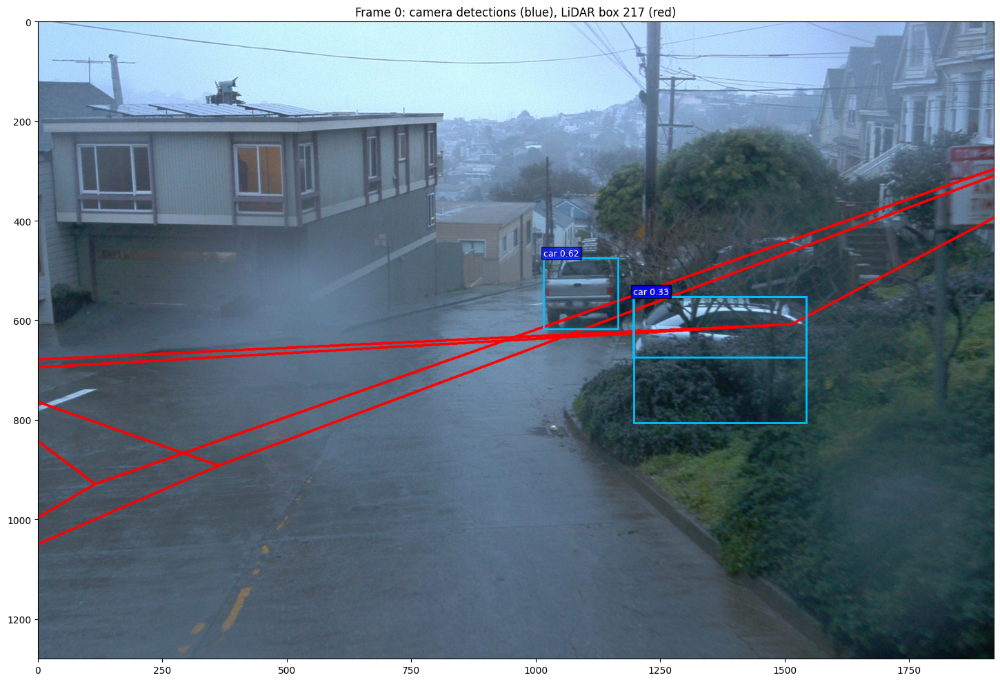

Camera detections recovered: 3
LiDAR box projected bounds: [     -534.4       104.5      2468.9        1205]


In [147]:
# Runs camera inference separately and visualizes the problematic detection.
import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from src.models.camera_detector import predict_camera

# Run ONLY camera inference to recover the missing camera detections.
camera_output = predict_camera(camera_model, frame["image"], confidence=0.25)

# Find the existing LiDAR detection; do not rerun LiDAR inference.
target = np.array([6.3798, 5.393, 0.78418])
detection = next(
    d for d in lidar_detections
    if np.allclose(np.asarray(d["box"], dtype=float)[:3], target, atol=0.02)
)

# Construct the 3D box corners.
cx, cy, cz, dx, dy, dz, heading = map(float, detection["box"])
c, s = np.cos(heading), np.sin(heading)
local_xy = np.array([
    [-dx/2, -dy/2], [dx/2, -dy/2],
    [dx/2, dy/2], [-dx/2, dy/2],
])
xy = local_xy @ np.array([[c, -s], [s, c]]).T + [cx, cy]

corners_vehicle = np.vstack([
    np.column_stack([xy, np.full(4, cz-dz/2)]),
    np.column_stack([xy, np.full(4, cz+dz/2)]),
])
corners_h = np.column_stack([corners_vehicle, np.ones(8)])
cam = (geometry["T_camera_vehicle"] @ corners_h.T).T[:, :3]
corners_cv = np.column_stack([-cam[:, 1], -cam[:, 2], cam[:, 0]])

uv, _ = cv2.projectPoints(
    corners_cv, np.zeros(3), np.zeros(3),
    geometry["K"], geometry["dist"]
)
uv = uv.reshape(-1, 2)

# Draw on the original image.
image = np.asarray(frame["image"]).copy()
edges = [
    (0,1),(1,2),(2,3),(3,0),
    (4,5),(5,6),(6,7),(7,4),
    (0,4),(1,5),(2,6),(3,7)
]
for i, j in edges:
    if corners_cv[i, 2] > 0.1 and corners_cv[j, 2] > 0.1:
        p1 = tuple(np.round(uv[i]).astype(int))
        p2 = tuple(np.round(uv[j]).astype(int))
        cv2.line(image, p1, p2, (255, 0, 0), 3)

fig, ax = plt.subplots(figsize=(16, 10))
ax.imshow(image)

names = camera_output["names"]
for box, score, label in zip(
    camera_output["boxes"], camera_output["scores"], camera_output["labels"]
):
    x1, y1, x2, y2 = map(float, box)
    ax.add_patch(Rectangle(
        (x1, y1), x2-x1, y2-y1,
        fill=False, edgecolor="deepskyblue", linewidth=2
    ))
    class_name = names[int(label)] if isinstance(names, dict) else names[int(label)]
    ax.text(
        x1, max(0, y1-5), f"{class_name} {float(score):.2f}",
        color="white", fontsize=9,
        bbox=dict(facecolor="blue", alpha=0.7, pad=2)
    )

ax.set_title("Frame 0: camera detections (blue), LiDAR box 217 (red)")
ax.set_xlim(0, image.shape[1])
ax.set_ylim(image.shape[0], 0)
plt.tight_layout()
plt.show()

print("Camera detections recovered:", len(camera_output["boxes"]))
print("LiDAR box projected bounds:", np.round([
    uv[:, 0].min(), uv[:, 1].min(),
    uv[:, 0].max(), uv[:, 1].max()
], 1))

In [151]:
# Reloads the projection and runner modules, then reruns fusion.
import importlib
import src.fusion.projection as projection

# Reload the updated projection function.
importlib.reload(projection)

# Ensure runner uses the reloaded function.
import src.fusion.runner as runner
importlib.reload(runner)

# Run fusion for frame 0 using your existing configuration.
# Replace `cfg` with the configuration variable used in your notebook,
# if it has a different name.
test_result = runner_module.run_fusion_frame(
    frame_idx=0,
    detector=detector,
    lidar_model=lidar_model,
    cfg=cfg,
    camera_model=camera_model,
    context_dir=context_dir,
    save_visualization=True,
)

print(result)

print("LiDAR detections:", test_result["num_lidar_detections"])
print("Projected boxes:", test_result["num_projected_boxes"])
print("Camera detections:", test_result["num_camera_detections"])
print("Matches:", test_result["num_matches"])
print("Mean IoU:", test_result["mean_matched_iou"])
print("Visualization:", test_result["visualization_path"])

{'frame_idx': 0, 'num_points_raw': 165170, 'num_points_model': 165170, 'num_lidar_detections': 360, 'num_camera_detections': 3, 'num_camera_candidates': 3, 'num_projected_boxes': 194, 'num_matches': 1, 'mean_matched_iou': 0.5682364458913775, 'lidar_inference_seconds': 2.9630657880006765, 'camera_inference_seconds': 0.21582878499975777, 'total_seconds': 4.341475428000194, 'csv_path': '/content/drive/MyDrive/Colab Notebooks/3DPerception/project/experiments/experiment_1_results/experiment_1_detections.csv', 'visualization_path': '/content/drive/MyDrive/Colab Notebooks/3DPerception/project/experiments/experiment_1_results/frame_000_fusion.jpg', 'iou_matrix': array([[          0,           0,           0],
       [          0,           0,           0],
       [          0,           0,           0],
       ...,
       [          0,           0,           0],
       [          0,           0,           0],
       [          0,           0,           0]]), 'matches': [(15, 2, 0.5682364458913

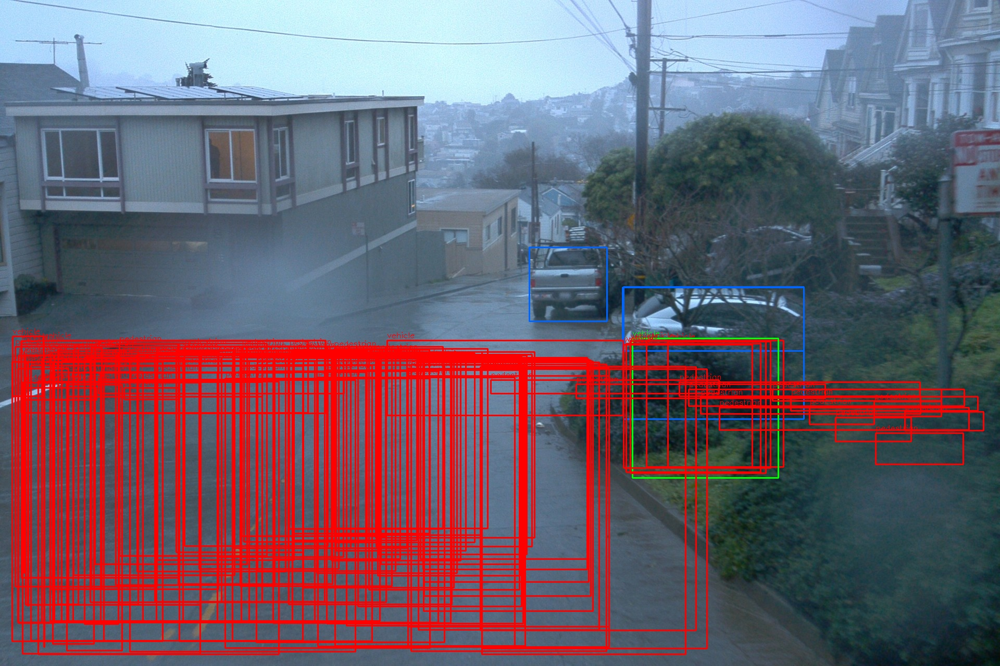

In [152]:
# Displays the visualization from prev cell.
from PIL import Image
from IPython.display import display

display(Image.open(test_result["visualization_path"]))

In [153]:
# Prints the transformation matrix, translation and origin relationship.
import numpy as np

T = np.asarray(geometry["T_camera_vehicle"])
T_inv = np.linalg.inv(T)

print("T_camera_vehicle rotation:")
print(np.round(T[:3, :3], 4))
print("\nT_camera_vehicle translation:")
print(np.round(T[:3, 3], 4))

print("\nCamera origin in vehicle coordinates:")
print(np.round(T_inv[:3, 3], 4))

print("\nVehicle origin in camera-aligned coordinates:")
print(np.round(T[:3, 3], 4))

print("\nCalibration extrinsic keys:", calibration.keys())

T_camera_vehicle rotation:
[[          1     -0.0032     -0.0057]
 [     0.0031      0.9998     -0.0179]
 [     0.0058      0.0179      0.9998]]

T_camera_vehicle translation:
[    -1.5271      0.0571     -2.1238]

Camera origin in vehicle coordinates:
[     1.5391      -0.024      2.1158]

Vehicle origin in camera-aligned coordinates:
[    -1.5271      0.0571     -2.1238]

Calibration extrinsic keys: dict_keys(['camera_name', 'context', 'intrinsic', 'extrinsic', 'width', 'height', 'rolling_shutter_direction'])


In [154]:
# Tests the calibration extrinsic and transformed forward direction.
import numpy as np

T = np.asarray(calibration["extrinsic"], dtype=float)
T_inv = np.linalg.inv(T)

print("Original extrinsic translation:", np.round(T[:3, 3], 4))
print("Inverse translation:", np.round(T_inv[:3, 3], 4))

# Test the camera optical axis: OpenCV forward is +Z.
# Under the assumed Waymo camera-aligned convention, forward is +X.
camera_forward = np.array([1.0, 0.0, 0.0, 0.0])

print("\nForward axis transformed by original rotation:")
print(np.round(T[:3, :3] @ camera_forward[:3], 4))

print("\nForward axis transformed by inverse rotation:")
print(np.round(T_inv[:3, :3] @ camera_forward[:3], 4))

print("\nCalibration camera name:", calibration["camera_name"])
print("Calibration image dimensions:",
      calibration["width"], "x", calibration["height"])

Original extrinsic translation: [     1.5391      -0.024      2.1158]
Inverse translation: [    -1.5271      0.0571     -2.1238]

Forward axis transformed by original rotation:
[          1     -0.0032     -0.0057]

Forward axis transformed by inverse rotation:
[          1      0.0031      0.0058]

Calibration camera name: 1
Calibration image dimensions: 1920 x 1280


Raw LiDAR points: 165170
Points in front of camera: 20000
Points projected inside image: 6566


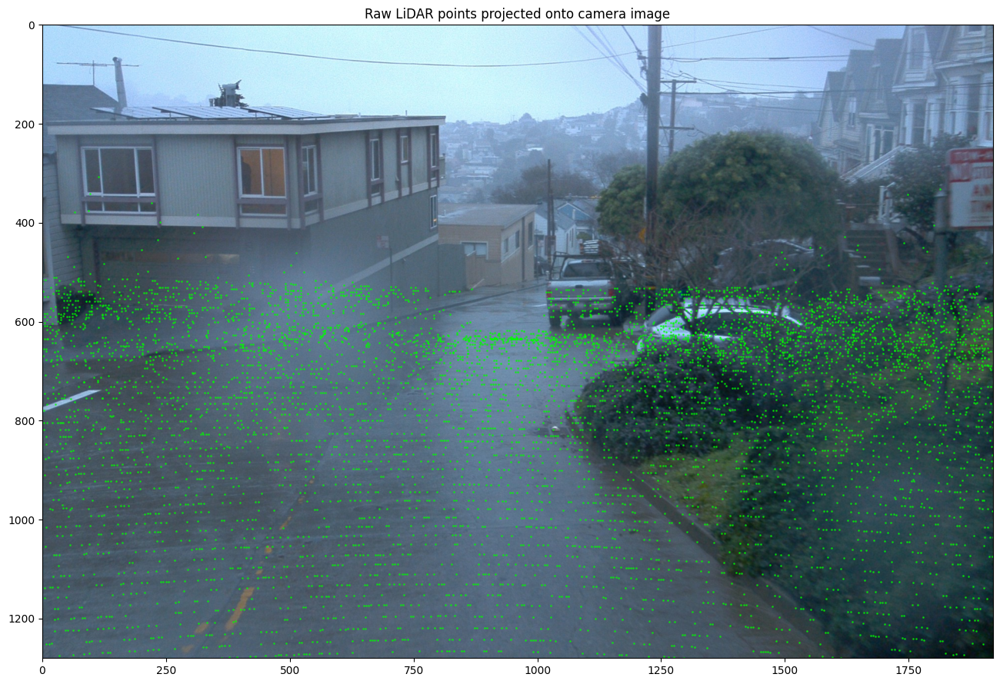

In [156]:
# Projects LiDAR points into the image and visualizes the points that fall within it.
import numpy as np
import cv2
import matplotlib.pyplot as plt

points = np.asarray(frame["points"])[:, :3]
points = points[np.isfinite(points).all(axis=1)]

# Vehicle frame -> camera-aligned frame -> OpenCV optical frame.
T = geometry["T_camera_vehicle"]
points_h = np.column_stack([points, np.ones(len(points))])
camera = (T @ points_h.T).T[:, :3]

points_cv = np.column_stack([
    -camera[:, 1],
    -camera[:, 2],
    camera[:, 0],
])

# Keep points in front of the camera.
front = points_cv[:, 2] > 0.1
points_cv = points_cv[front]

# Subsample for a readable plot.
rng = np.random.default_rng(42)
if len(points_cv) > 20000:
    points_cv = points_cv[
        rng.choice(len(points_cv), 20000, replace=False)
    ]

uv, _ = cv2.projectPoints(
    points_cv, np.zeros(3), np.zeros(3),
    geometry["K"], geometry["dist"]
)
uv = uv.reshape(-1, 2)

# Keep only projected points inside the actual image.
w = geometry["image_width"]
h = geometry["image_height"]
valid = (
    np.isfinite(uv).all(axis=1)
    & (uv[:, 0] >= 0) & (uv[:, 0] < w)
    & (uv[:, 1] >= 0) & (uv[:, 1] < h)
)

print("Raw LiDAR points:", len(points))
print("Points in front of camera:", len(points_cv))
print("Points projected inside image:", int(valid.sum()))

image = np.asarray(frame["image"])
plt.figure(figsize=(14, 9))
plt.imshow(image)
plt.scatter(
    uv[valid, 0], uv[valid, 1],
    s=1, c="lime", alpha=0.6
)
plt.xlim(0, w)
plt.ylim(h, 0)
plt.title("Raw LiDAR points projected onto camera image")
plt.tight_layout()
plt.show()

In [157]:
# Counts points inside the full 3D volume of a selected detection.
import numpy as np

target = np.array([6.3798, 5.393, 0.78418])
det = next(
    d for d in lidar_detections
    if np.allclose(np.asarray(d["box"], dtype=float)[:3], target, atol=0.02)
)

box = np.asarray(det["box"], dtype=float)
cx, cy, cz, dx, dy, dz, heading = box

pts = np.asarray(frame["points"])[:, :3]
delta = pts[:, :2] - [cx, cy]
c, s = np.cos(heading), np.sin(heading)

local_x = delta[:, 0] * c + delta[:, 1] * s
local_y = -delta[:, 0] * s + delta[:, 1] * c

inside = (
    np.isfinite(pts).all(axis=1)
    & (np.abs(local_x) <= dx / 2)
    & (np.abs(local_y) <= dy / 2)
    & (np.abs(pts[:, 2] - cz) <= dz / 2)
)
selected = pts[inside]

print("Box [cx, cy, cz, dx, dy, dz, heading]:")
print(np.round(box, 3))
print("LiDAR points inside 3D box:", len(selected))

if len(selected):
    print("Point XYZ min:", np.round(selected.min(axis=0), 3))
    print("Point XYZ max:", np.round(selected.max(axis=0), 3))

Box [cx, cy, cz, dx, dy, dz, heading]:
[       6.38       5.393       0.784       1.125        1.01       1.835      -1.589]
LiDAR points inside 3D box: 0


In [159]:
# Compares point counts inside the BEV footprint and the full 3D box.
import numpy as np

det = next(
    d for d in lidar_detections
    if np.allclose(
        np.asarray(d["box"], dtype=float)[:3],
        [6.3798, 5.393, 0.78418],
        atol=0.02,
    )
)

cx, cy, cz, dx, dy, dz, heading = map(float, det["box"])
pts = np.asarray(frame["points"])[:, :3]

delta = pts[:, :2] - np.array([cx, cy])
c, s = np.cos(heading), np.sin(heading)
local_x = delta[:, 0] * c + delta[:, 1] * s
local_y = -delta[:, 0] * s + delta[:, 1] * c

finite = np.isfinite(pts).all(axis=1)
inside_bev = (
    finite
    & (np.abs(local_x) <= dx / 2)
    & (np.abs(local_y) <= dy / 2)
)
inside_3d = inside_bev & (np.abs(pts[:, 2] - cz) <= dz / 2)

print(f"Points inside BEV footprint: {inside_bev.sum()}")
print(f"Points inside full 3D box:   {inside_3d.sum()}")
print(f"Box vertical range:          [{cz-dz/2:.3f}, {cz+dz/2:.3f}] m")

if inside_bev.any():
    z = pts[inside_bev, 2]
    print(f"BEV points Z range:           [{z.min():.3f}, {z.max():.3f}] m")

Points inside BEV footprint: 131
Points inside full 3D box:   0
Box vertical range:          [-0.133, 1.702] m
BEV points Z range:           [-0.210, -0.147] m


In [160]:
# Examines the height distribution of points inside the BEV footprint.
import numpy as np

z = pts[inside_bev, 2]

print("BEV points Z percentiles:")
print(np.percentile(z, [0, 25, 50, 75, 100]))

print("\nPredicted box vertical range:",
      (cz - dz/2, cz + dz/2))

print("\nBEV points within predicted vertical range:",
      np.sum((z >= cz - dz/2) & (z <= cz + dz/2)))

BEV points Z percentiles:
[   -0.21034    -0.19235     -0.1848    -0.17083    -0.14731]

Predicted box vertical range: (-0.13321064755478385, 1.7015766982749987)

BEV points within predicted vertical range: 0


In [161]:
# Performs the same BEV-versus-3D point-support check across all detections.
import numpy as np

pts = np.asarray(frame["points"])[:, :3]
pts = pts[np.isfinite(pts).all(axis=1)]

results = []

for i, det in enumerate(lidar_detections):
    cx, cy, cz, dx, dy, dz, heading = map(float, det["box"])
    if min(dx, dy, dz) <= 0:
        continue

    delta = pts[:, :2] - [cx, cy]
    c, s = np.cos(heading), np.sin(heading)
    lx = delta[:, 0] * c + delta[:, 1] * s
    ly = -delta[:, 0] * s + delta[:, 1] * c

    bev = (np.abs(lx) <= dx/2) & (np.abs(ly) <= dy/2)
    full = bev & (np.abs(pts[:, 2] - cz) <= dz/2)

    results.append((i, det["label"], int(bev.sum()), int(full.sum())))

bev_counts = np.array([r[2] for r in results])
full_counts = np.array([r[3] for r in results])

print("Valid detections:", len(results))
print("Detections with BEV points:", int((bev_counts > 0).sum()))
print("Detections with 3D points:", int((full_counts > 0).sum()))
print("Detections with BEV points but zero 3D points:",
      int(((bev_counts > 0) & (full_counts == 0)).sum()))

print("\nFirst 15 detections: (index, label, BEV points, 3D points)")
for row in results[:15]:
    print(row)

Valid detections: 360
Detections with BEV points: 318
Detections with 3D points: 275
Detections with BEV points but zero 3D points: 43

First 15 detections: (index, label, BEV points, 3D points)
(0, 0, 409, 39)
(1, 0, 483, 77)
(2, 0, 650, 131)
(3, 0, 755, 188)
(4, 0, 435, 26)
(5, 0, 519, 33)
(6, 0, 636, 63)
(7, 0, 723, 83)
(8, 0, 589, 16)
(9, 0, 236, 0)
(10, 0, 248, 0)
(11, 0, 3617, 3617)
(12, 0, 2978, 2978)
(13, 0, 367, 0)
(14, 0, 459, 0)


In [162]:
# Summarizes point support by detection class.
from collections import defaultdict

by_class = defaultdict(list)

for _, label, bev_count, full_count in results:
    by_class[label].append((bev_count, full_count))

for label, values in sorted(by_class.items()):
    arr = np.asarray(values)
    print(
        f"Class {label}: {len(values)} detections | "
        f"BEV points: {(arr[:, 0] > 0).sum()} | "
        f"3D points: {(arr[:, 1] > 0).sum()} | "
        f"BEV-only: {((arr[:, 0] > 0) & (arr[:, 1] == 0)).sum()}"
    )

Class 0: 32 detections | BEV points: 32 | 3D points: 21 | BEV-only: 11
Class 1: 328 detections | BEV points: 286 | 3D points: 254 | BEV-only: 32


In [163]:
# Calls inspect_box_projection on selected boxes, including the problematic pedestrian.
from src.fusion.projection_diagnostics import inspect_box_projection

# Pick detections with actual 3D point support, plus the problematic pedestrian.
selected_indices = [
    i for i, det in enumerate(lidar_detections)
    if results[i][3] > 0
][:5]

pedestrian_idx = next(
    i for i, det in enumerate(lidar_detections)
    if np.allclose(
        np.asarray(det["box"], dtype=float)[:3],
        [6.3798, 5.393, 0.78418],
        atol=0.02,
    )
)
if pedestrian_idx not in selected_indices:
    selected_indices.append(pedestrian_idx)

for i in selected_indices:
    report = inspect_box_projection(
        lidar_detections[i],
        frame["points"],
        geometry["T_camera_vehicle"],
        geometry["K"],
        geometry["dist"],
        geometry["image_width"],
        geometry["image_height"],
    )
    print(f"\nDetection {i} | class {lidar_detections[i]['label']}")
    for key, value in report.items():
        print(f"  {key}: {np.round(value, 2) if isinstance(value, list) else value}")


Detection 0 | class 0
  box: [     -18.97       -5.58        1.02        5.37        2.08         2.6        0.01]
  front_corners: 0
  camera_center_xyz: [     -20.49        -5.6       -1.31]
  depth_range: [     -23.19      -17.78]
  points_in_bev: 409
  points_in_3d: 39
  undistorted_bounds: None
  distorted_bounds: None

Detection 1 | class 0
  box: [     -18.49       -5.61        1.03        5.23        1.99        2.58        0.03]
  front_corners: 0
  camera_center_xyz: [        -20       -5.63        -1.3]
  depth_range: [     -22.65      -17.35]
  points_in_bev: 483
  points_in_3d: 77
  undistorted_bounds: None
  distorted_bounds: None

Detection 2 | class 0
  box: [     -18.05       -5.67        1.05        5.63        2.03        2.52        0.02]
  front_corners: 0
  camera_center_xyz: [     -19.57       -5.69       -1.28]
  depth_range: [     -22.41      -16.72]
  points_in_bev: 650
  points_in_3d: 131
  undistorted_bounds: None
  distorted_bounds: None

Detection 3 | cla

In [164]:
# Finds cases where distorted and undistorted projected bounds intersect the image differently.
from src.fusion.projection_diagnostics import inspect_box_projection

w = geometry["image_width"]
h = geometry["image_height"]

false_intersections = []
for i, det in enumerate(lidar_detections):
    r = inspect_box_projection(
        det, frame["points"],
        geometry["T_camera_vehicle"],
        geometry["K"], geometry["dist"], w, h,
    )
    u = r["undistorted_bounds"]
    d = r["distorted_bounds"]
    if u is None or d is None:
        continue

    undistorted_intersects = (
        u[2] >= 0 and u[0] <= w and u[3] >= 0 and u[1] <= h
    )
    distorted_intersects = (
        d[2] >= 0 and d[0] <= w and d[3] >= 0 and d[1] <= h
    )

    if not undistorted_intersects and distorted_intersects:
        false_intersections.append((i, u, d))

print("Potential false image intersections:", len(false_intersections))
for i, u, d in false_intersections[:10]:
    print(f"Detection {i}: undistorted={np.round(u, 1)}, distorted={np.round(d, 1)}")

Potential false image intersections: 86
Detection 30: undistorted=[     -885.8       664.2        -8.3       871.4], distorted=[     -539.3       660.6         0.7       862.1]
Detection 46: undistorted=[     3810.9       878.9        6768      3071.3], distorted=[-1.5547e+05      -65690       208.7       571.5]
Detection 49: undistorted=[     2143.6       852.5      3183.4      2032.1], distorted=[     1364.1       805.4        2434      1622.6]
Detection 50: undistorted=[     2023.4       881.3      3224.6      2260.6], distorted=[      865.6       569.8        2426      1717.5]
Detection 183: undistorted=[    -1537.3       801.1      -468.8      1779.7], distorted=[     -526.7         638       947.7      1416.2]
Detection 184: undistorted=[    -1248.3       775.7      -335.7      1654.2], distorted=[       -530       741.3        71.4      1432.9]
Detection 193: undistorted=[    -2149.1       807.7      -926.5      1921.4], distorted=[     -530.2     -1005.2      4944.2      1276.3

In [168]:
# Reloads the projection/runner modules and prints the projection function source.
import importlib
import src.fusion.projection as projection
import src.fusion.runner as runner

importlib.reload(projection)
importlib.reload(runner)

print(inspect.getsource(projection.project_lidar_box))

def project_lidar_box(
    box, points_vehicle, T_camera_vehicle, K, dist,
    image_width, image_height, min_points=10
):
    """Project a 3D vehicle-frame box into a distorted camera image."""
    x, y, cz, sx, sy, dz, heading = map(float, box)
    if sx <= 0 or sy <= 0 or dz <= 0 or len(points_vehicle) == 0:
        return None

    # Require LiDAR support in the oriented BEV footprint.
    pts = np.asarray(points_vehicle)
    finite = np.isfinite(pts[:, :3]).all(axis=1)
    c, s = np.cos(heading), np.sin(heading)
    dxp, dyp = pts[:, 0] - x, pts[:, 1] - y
    lx = dxp * c + dyp * s
    ly = -dxp * s + dyp * c
    inside = finite & (np.abs(lx) <= sx / 2) & (np.abs(ly) <= sy / 2)
    if inside.sum() < min_points:
        return None

    # Construct the eight corners in vehicle coordinates.
    local_xy = np.array([
        [-sx/2, -sy/2], [sx/2, -sy/2],
        [sx/2, sy/2], [-sx/2, sy/2],
    ])
    xy = local_xy @ np.array([[c, -s], [s, c]]).T + [x, y]
    corners = np.vstack([
 

In [171]:
# Collects and sorts the projected bounding boxes by image area.
import numpy as np
from src.fusion.projection import project_lidar_box

reports = []

for i, det in enumerate(lidar_detections):
    box = np.asarray(det["box"], dtype=float)
    bbox = project_lidar_box(
        box, frame["points"],
        geometry["T_camera_vehicle"],
        geometry["K"], geometry["dist"],
        geometry["image_width"], geometry["image_height"],
    )
    if bbox is not None:
        x1, y1, x2, y2 = bbox
        reports.append({
            "index": i,
            "class": det["label"],
            "dimensions": np.round(box[3:6], 2).tolist(),
            "center_vehicle": np.round(box[:3], 2).tolist(),
            "bbox": np.round(bbox, 1).tolist(),
            "bbox_size": [round(x2-x1, 1), round(y2-y1, 1)],
        })

reports.sort(key=lambda r: r["bbox_size"][0] * r["bbox_size"][1], reverse=True)

for r in reports[:10]:
    print(r)

{'index': 64, 'class': 1, 'dimensions': [1.1, 0.99, 1.76], 'center_vehicle': [6.33, -1.61, 0.9], 'bbox': [1334.5, 763.2, 1911.9, 1279.4], 'bbox_size': [577.4, 516.2]}
{'index': 65, 'class': 1, 'dimensions': [1.06, 0.97, 1.74], 'center_vehicle': [6.83, -1.62, 0.91], 'bbox': [1312.3, 748.9, 1851.4, 1279.5], 'bbox_size': [539.1, 530.6]}
{'index': 136, 'class': 1, 'dimensions': [1.16, 1.01, 1.76], 'center_vehicle': [7.41, 1.9, 0.84], 'bbox': [8.8, 734.2, 503.6, 1278.4], 'bbox_size': [494.8, 544.2]}
{'index': 63, 'class': 1, 'dimensions': [1.13, 1.01, 1.78], 'center_vehicle': [5.84, -1.61, 0.87], 'bbox': [1371.0, 783.9, 1911.9, 1279.1], 'bbox_size': [540.8, 495.2]}
{'index': 70, 'class': 1, 'dimensions': [1.1, 0.98, 1.74], 'center_vehicle': [7.34, -1.1, 0.91], 'bbox': [1097.1, 738.6, 1584.0, 1280.0], 'bbox_size': [486.9, 541.4]}
{'index': 121, 'class': 1, 'dimensions': [1.14, 1.0, 1.77], 'center_vehicle': [7.42, 1.4, 0.87], 'bbox': [187.9, 729.8, 660.7, 1279.5], 'bbox_size': [472.8, 549.7]}

In [172]:
# Transforms a selected detection center into camera coordinates.
import numpy as np

det = lidar_detections[64]
box = np.asarray(det["box"], dtype=float)
center_vehicle = np.array([*box[:3], 1.0])

center_cam = geometry["T_camera_vehicle"] @ center_vehicle

print("Vehicle-frame center:", center_vehicle[:3])
print("Transformed center:", center_cam[:3])
print("Current assumed optical coordinates:",
      [-center_cam[1], -center_cam[2], center_cam[0]])
print("Calibration extrinsic:")
print(calibration["extrinsic"])

Vehicle-frame center: [     6.3343     -1.6132     0.89522]
Transformed center: [     4.8072      -1.552     -1.2212]
Current assumed optical coordinates: [np.float64(1.552004366978786), np.float64(1.221160677285683), np.float64(4.807151059879265)]
Calibration extrinsic:
[[0.9999785086634438, 0.003142074430868787, 0.005754092413724721, 1.5391467608686606], [-0.0032444997400664865, 0.999834903267396, 0.017878462733512377, -0.02402951085443307], [-0.005696966971249904, -0.017896747652793314, 0.9998236099386635, 2.115778469674332], [0.0, 0.0, 0.0, 1.0]]


In [173]:
# Compares alternative camera-axis conversions and their projected centers.
import cv2
import numpy as np

center_cam = geometry["T_camera_vehicle"] @ np.array([
    *np.asarray(lidar_detections[64]["box"], dtype=float)[:3], 1.0
])

candidates = {
    "current_axis_conversion": np.array([
        -center_cam[1], -center_cam[2], center_cam[0]
    ]),
    "direct_optical_coordinates": center_cam[:3],
}

for name, point in candidates.items():
    print(f"\n{name}: {point}")

    if point[2] <= 0:
        print("Behind camera")
        continue

    uv, _ = cv2.projectPoints(
        point.reshape(1, 1, 3),
        np.zeros(3), np.zeros(3),
        geometry["K"], geometry["dist"]
    )
    print("Projected center (u, v):", uv.reshape(2))


current_axis_conversion: [      1.552      1.2212      4.8072]
Projected center (u, v): [     1615.5      1156.1]

direct_optical_coordinates: [     4.8072      -1.552     -1.2212]
Behind camera


In [175]:
# Identifies same-class LiDAR detections with BEV IoU at least 0.50.
from src.fusion.detection_diagnostics import summarize_overlaps

overlap_pairs = summarize_overlaps(lidar_detections, threshold=0.5)

print("Total detections:", len(lidar_detections))
print("Same-class pairs with BEV IoU >= 0.5:", len(overlap_pairs))
print("First 20 pairs:", overlap_pairs[:20])

Total detections: 360
Same-class pairs with BEV IoU >= 0.5: 50
First 20 pairs: [(0, 1, 0.7928660043811373), (0, 2, 0.6524803667806276), (0, 3, 0.5502819985149099), (0, 4, 0.6427139144071958), (0, 5, 0.6139086732750372), (0, 6, 0.573864008749697), (1, 2, 0.798562856686817), (1, 3, 0.674694586571496), (1, 4, 0.5242216114520704), (1, 5, 0.6498353018224096), (1, 6, 0.6510486286840678), (1, 7, 0.5670081772898214), (2, 3, 0.8433884572634371), (2, 5, 0.5334933237987595), (2, 6, 0.6446912872774281), (2, 7, 0.6198823310260044), (3, 6, 0.5715282181412553), (3, 7, 0.6420371994851042), (4, 5, 0.773846279780383), (4, 6, 0.623558652755117)]


In [176]:
# Counts how many detections are involved in overlapping pairs.
from collections import Counter

overlap_counts = Counter()
for i, j, iou in overlap_pairs:
    overlap_counts[i] += 1
    overlap_counts[j] += 1

involved = sorted(overlap_counts)

print("Detections involved in overlapping pairs:", len(involved))
print("Detections not involved:", len(lidar_detections) - len(involved))
print("\nMost connected detections:")

for i, count in overlap_counts.most_common(15):
    det = lidar_detections[i]
    box = det["box"]
    print(
        f"idx={i:3d}, class={det['label']}, "
        f"overlap_count={count:2d}, "
        f"center={box[:3]}, dims={box[3:6]}"
    )

Detections involved in overlapping pairs: 28
Detections not involved: 332

Most connected detections:
idx=  6, class=0, overlap_count= 8, center=[np.float64(-18.150029495358467), np.float64(-5.294930629432201), 0.9554440379142761], dims=[5.270653908217126, 1.9622966325861362, 2.2395098153939466]
idx=  1, class=0, overlap_count= 7, center=[np.float64(-18.486636847257614), np.float64(-5.6093710064888), 1.0321249961853027], dims=[5.229198483877548, 1.9870523366246577, 2.58047776660665]
idx=  5, class=0, overlap_count= 7, center=[np.float64(-18.56965923309326), np.float64(-5.223426923155785), 0.9666686058044434], dims=[5.0394180847153836, 1.9460287093774529, 2.3057126236007828]
idx=  7, class=0, overlap_count= 7, center=[np.float64(-17.726940467953682), np.float64(-5.300502724945545), 0.9307680726051331], dims=[5.17133203547688, 1.9312894066834667, 2.196803214131832]
idx=  0, class=0, overlap_count= 6, center=[np.float64(-18.974046856164932), np.float64(-5.577946454286575), 1.0217163562774

In [177]:
# Counts detections whose centers are behind the camera, outside the image, or inside it.
import numpy as np

K = geometry["K"]
T = geometry["T_camera_vehicle"]
w = geometry["image_width"]
h = geometry["image_height"]

counts = {
    "behind_camera": 0,
    "in_front_outside_image": 0,
    "center_inside_image": 0,
}

for det in lidar_detections:
    box = np.asarray(det["box"], dtype=float)
    center = np.array([*box[:3], 1.0])
    cam = T @ center

    # Convert to OpenCV optical coordinates.
    optical = np.array([-cam[1], -cam[2], cam[0]])

    if optical[2] <= 0.1:
        counts["behind_camera"] += 1
        continue

    u = K[0, 0] * optical[0] / optical[2] + K[0, 2]
    v = K[1, 1] * optical[1] / optical[2] + K[1, 2]

    if 0 <= u < w and 0 <= v < h:
        counts["center_inside_image"] += 1
    else:
        counts["in_front_outside_image"] += 1

print(counts)

{'behind_camera': 21, 'in_front_outside_image': 212, 'center_inside_image': 127}


In [178]:
# Projects boxes whose centers fall inside the image.
import numpy as np
from src.fusion.projection import project_lidar_box

K = geometry["K"]
T = geometry["T_camera_vehicle"]
w, h = geometry["image_width"], geometry["image_height"]

visible = []

for i, det in enumerate(lidar_detections):
    box = np.asarray(det["box"], dtype=float)
    center = T @ np.array([*box[:3], 1.0])
    optical = np.array([-center[1], -center[2], center[0]])

    if optical[2] <= 0.1:
        continue

    u = K[0, 0] * optical[0] / optical[2] + K[0, 2]
    v = K[1, 1] * optical[1] / optical[2] + K[1, 2]

    if 0 <= u < w and 0 <= v < h:
        bbox = project_lidar_box(
            box, frame["points"], T, K, geometry["dist"], w, h
        )
        visible.append((i, det["label"], round(u, 1), round(v, 1),
                        np.round(box[3:6], 2).tolist(), bbox))

print("Visible centers:", len(visible))
for row in visible[:20]:
    print(row)

Visible centers: 127
(9, 0, np.float64(1371.2), np.float64(766.7), [3.14, 1.5, 1.88], [1282.1203004077477, 656.5140009678316, 1479.4114222337505, 899.1432653795791])
(10, 0, np.float64(1360.1), np.float64(764.2), [3.59, 1.6, 1.92], [1241.453448855843, 654.1197499749082, 1504.9239159594144, 897.7722299023494])
(13, 0, np.float64(1340.0), np.float64(771.6), [3.36, 1.61, 1.96], [1214.071317770194, 650.4980786367288, 1494.1252787322903, 918.9150334877341])
(14, 0, np.float64(1327.9), np.float64(770.4), [3.34, 1.59, 1.91], [1210.7029161954622, 655.2226943709061, 1470.6623111635133, 909.7473495949762])
(15, 0, np.float64(1318.4), np.float64(771.9), [3.57, 1.65, 1.87], [1202.7330776841975, 660.8583637917998, 1460.5487281551807, 907.542354192206])
(16, 0, np.float64(1308.0), np.float64(769.1), [3.65, 1.67, 1.85], [1197.1940632735127, 662.0237695968593, 1444.190498006723, 899.7803533718447])
(21, 0, np.float64(978.8), np.float64(720.2), [6.31, 2.37, 1.76], [743.746814910319, 654.7536392093693, 

In [179]:
# Examines projected centers and dimensions for two selected detections.
import numpy as np

for i in [9, 64]:
    box = np.asarray(lidar_detections[i]["box"], dtype=float)
    cx, cy, cz, dx, dy, dz, heading = box

    center_vehicle = np.array([cx, cy, cz, 1.0])
    center_cam = geometry["T_camera_vehicle"] @ center_vehicle
    center_cv = np.array([-center_cam[1], -center_cam[2], center_cam[0]])

    print(f"\nDetection {i}, class {lidar_detections[i]['label']}")
    print("Vehicle center:", np.round(center_vehicle[:3], 3))
    print("Optical center:", np.round(center_cv, 3))
    print("Dimensions:", np.round([dx, dy, dz], 3))
    print("Optical depth:", round(float(center_cv[2]), 3))


Detection 9, class 0
Vehicle center: [     19.772      -3.815       0.908]
Optical center: [      3.711       1.171      18.251]
Dimensions: [      3.139       1.496       1.881]
Optical depth: 18.251

Detection 64, class 1
Vehicle center: [      6.334      -1.613       0.895]
Optical center: [      1.552       1.221       4.807]
Dimensions: [      1.101       0.988       1.758]
Optical depth: 4.807


In [181]:
# Projects the eight corners of a selected 3D box into the image
import cv2
import numpy as np

i = 64
box = np.asarray(lidar_detections[i]["box"], dtype=float)
cx, cy, cz, dx, dy, dz, heading = box
c, s = np.cos(heading), np.sin(heading)

local_xy = np.array([
    [-dx/2, -dy/2], [dx/2, -dy/2],
    [dx/2, dy/2], [-dx/2, dy/2],
])
xy = local_xy @ np.array([[c, -s], [s, c]]).T + [cx, cy]
corners = np.vstack([
    np.column_stack([xy, np.full(4, cz - dz/2)]),
    np.column_stack([xy, np.full(4, cz + dz/2)]),
])
corners_h = np.column_stack([corners, np.ones(8)])
cam = (geometry["T_camera_vehicle"] @ corners_h.T).T[:, :3]
cv = np.column_stack([-cam[:, 1], -cam[:, 2], cam[:, 0]])

uv, _ = cv2.projectPoints(
    cv, np.zeros(3), np.zeros(3),
    geometry["K"], geometry["dist"]
)

print("Optical corners [x, y, depth]:\n", np.round(cv, 3))
print("Projected corners [u, v]:\n", np.round(uv.reshape(-1, 2), 1))

Optical corners [x, y, depth]:
 [[      0.998       2.093       4.305]
 [      2.098       2.113       4.331]
 [      2.075       2.107       5.319]
 [      0.974       2.087       5.293]
 [      1.029       0.336       4.295]
 [       2.13       0.355       4.321]
 [      2.106       0.349       5.309]
 [      1.006       0.329       5.283]]
Projected corners [u, v]:
 [[     1421.6      1618.2]
 [     1892.9        1581]
 [     1739.6      1433.4]
 [     1329.9      1442.6]
 [     1446.6       795.7]
 [     1956.1       801.9]
 [     1767.7       769.6]
 [       1345       763.2]]


Raw points overlaid: 4813


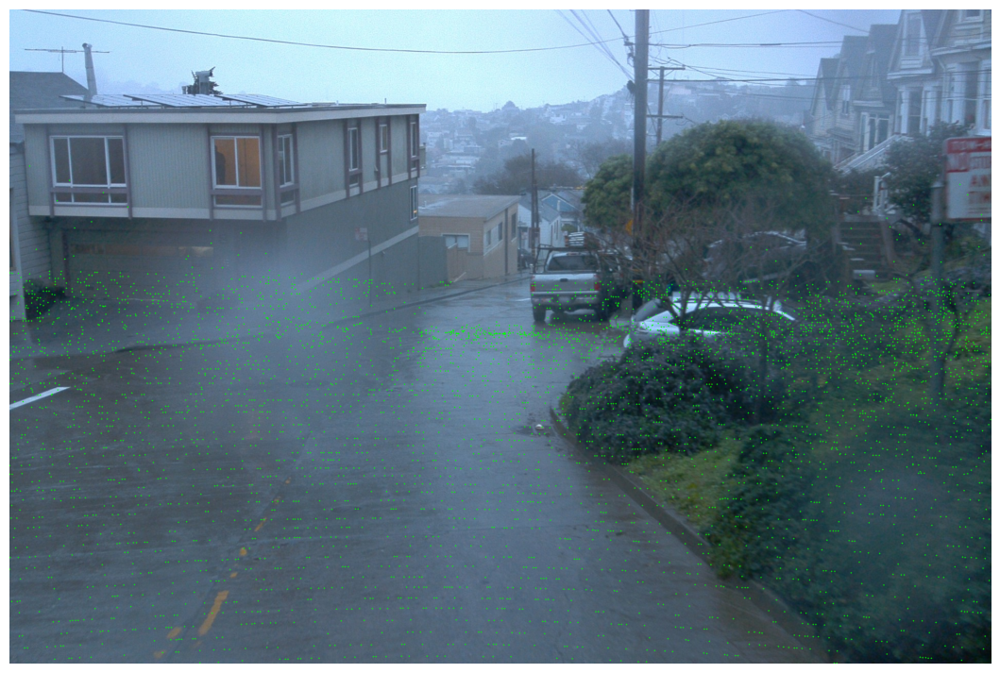

In [182]:
# Overlays projected LiDAR points on the camera image.
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Original RGB camera image and raw vehicle-frame LiDAR points
image = np.asarray(frame["image"]).copy()
points = np.asarray(frame["points"])[:, :3]

# Sample points for a readable overlay
rng = np.random.default_rng(42)
valid = np.isfinite(points).all(axis=1)
points = points[valid]
if len(points) > 30000:
    points = points[rng.choice(len(points), 30000, replace=False)]

# Vehicle -> camera-aligned -> OpenCV optical coordinates
points_h = np.column_stack([points, np.ones(len(points))])
cam = (geometry["T_camera_vehicle"] @ points_h.T).T[:, :3]
optical = np.column_stack([-cam[:, 1], -cam[:, 2], cam[:, 0]])

# Keep points in front of the camera
front = optical[:, 2] > 0.1
optical = optical[front]

uv, _ = cv2.projectPoints(
    optical, np.zeros(3), np.zeros(3),
    geometry["K"], geometry["dist"]
)
uv = uv.reshape(-1, 2)

# Draw only points inside the image
w, h = geometry["image_width"], geometry["image_height"]
inside = (
    np.isfinite(uv).all(axis=1)
    & (uv[:, 0] >= 0) & (uv[:, 0] < w)
    & (uv[:, 1] >= 0) & (uv[:, 1] < h)
)

overlay = image.copy()
for u, v in uv[inside].astype(int):
    cv2.circle(overlay, (u, v), 1, (0, 255, 0), -1)

print(f"Raw points overlaid: {inside.sum()}")

plt.figure(figsize=(16, 9))
plt.imshow(overlay)
plt.axis("off")
plt.show()

## Final Experiment Run and Results.

In [185]:
# Creates the experiment output directory.
from pathlib import Path

from src.setup_runtime import ROOT

FINAL_RESULTS_DIR = ROOT / "experiments" / "experiment_1_final"
FINAL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [198]:
# Reloads the runner and runs fusion on one frame, printing association statistics.
import importlib
import src.fusion.runner as runner

importlib.reload(runner)

result = runner.run_fusion_frame(
    frame_idx=0,
    detector=detector,
    lidar_model=lidar_model,
    cfg=cfg,
    camera_model=camera_model,
    output_dir=FINAL_RESULTS_DIR,
    save_visualization=True,
)

for key in (
    "num_lidar_detections",
    "num_projected_boxes",
    "num_unprojected_boxes",
    "num_camera_candidates",
    "num_eligible_pairs",
    "matches",
    "num_unmatched_projected_boxes",
    "num_unmatched_camera_candidates",
    "matched_ious",
    "mean_matched_iou",
):
    print(f"{key}: {result.get(key)}")

Converted context ready: /content/waymo_fusion_converted/10017090168044687777_6380_000_6400_000
num_lidar_detections: 360
num_projected_boxes: 121
num_unprojected_boxes: 239
num_camera_candidates: 3
num_eligible_pairs: 5
matches: [(13, 1, 0.3623192097191801)]
num_unmatched_projected_boxes: 120
num_unmatched_camera_candidates: 2
matched_ious: [0.3623192097191801]
mean_matched_iou: 0.3623192097191801


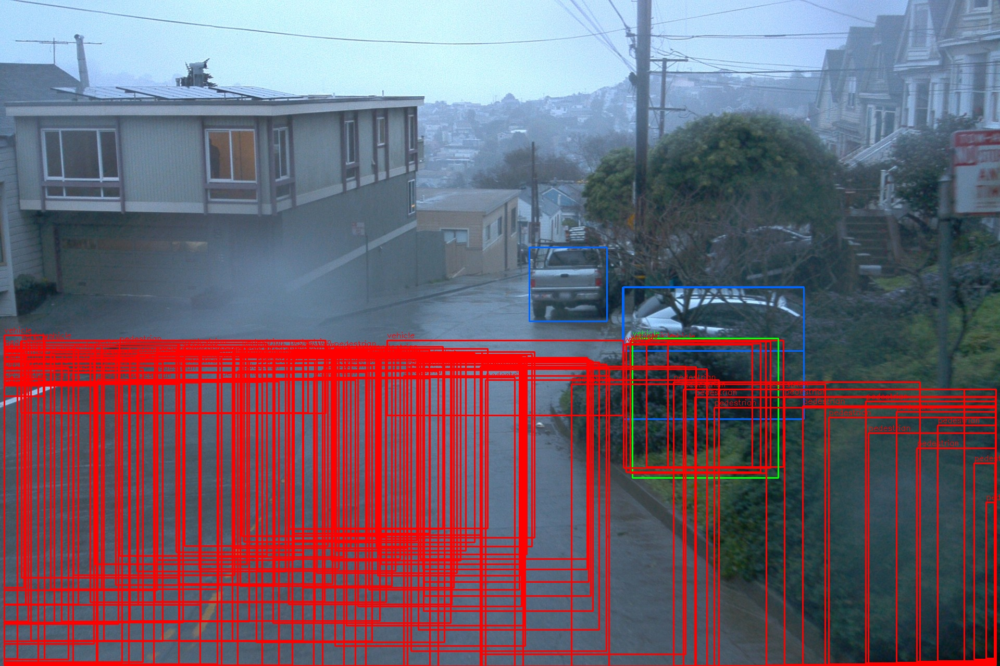

In [199]:
# Displays the single-frame fusion visualization.
from PIL import Image
from IPython.display import display

display(Image.open(result["visualization_path"]))

### Full experiment execution

Run the custom-trained PointPillars detector and YOLO camera detector
over the selected Waymo sequence. Save per-frame detections,
projection and association results, summary metrics, and
visualizations for subsequent analysis.


In [216]:
# Reloads and runs experiments.run_experiment_1.main(...).
import importlib
import experiments.run_experiment_1 as exp1

importlib.reload(exp1)

print("Run ID:", exp1.RUN_ID)
print("Output:", exp1.OUTPUT_DIR)

exp1.main(detector, lidar_model, cfg, camera_model)

Run ID: 20261022T021010Z
Output: /content/drive/MyDrive/Colab Notebooks/3DPerception/project/experiments/experiment_1_runs/20261022T021010Z
Converted context ready: /content/waymo_fusion_converted/10017090168044687777_6380_000_6400_000
Frames with camera + both LiDAR returns: 198
First available frame indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Run ID: 20261022T021010602077Z
Context: /content/waymo_fusion_converted/10017090168044687777_6380_000_6400_000
Frames selected: 198
Output: /content/drive/MyDrive/Colab Notebooks/3DPerception/project/experiments/experiment_1_runs/20261022T021010602077Z
[1/198] Frame 0
  LiDAR=360, projected=121, camera candidates=3, matches=1, mean IoU=0.3623192097191801
[2/198] Frame 1
  LiDAR=362, projected=115, camera candidates=3, matches=0, mean IoU=None
[3/198] Frame 2
  LiDAR=394, projected=137, camera candidates=3, matches=0, mean IoU=None
[4/198] Frame 3
  LiDAR=406, projected=140, camera candidates=3, matches=0, mean IoU=None
[5/198] Frame 4
  LiDAR=443, p

### Results and visualization

Generate plots from the saved experiment outputs to analyze
detection and projection counts, matches per frame, association
IoU distribution, and processing time.


In [220]:
# Runs the plotting script against the experiment's saved CSV outputs.
from pathlib import Path
import runpy
import sys

SCRIPT_PATH = Path("/content/experiments/plot_experiment_1.py")

assert SCRIPT_PATH.exists(), "Plotting script was not uploaded."
assert (RESULTS_DIR / "fusion_summary.csv").exists(), "Summary CSV not found."
assert (RESULTS_DIR / "fusion_matched_pairs.csv").exists(), "Matched-pairs CSV not found."

sys.argv = [
    str(SCRIPT_PATH),
    "--results-dir", str(RESULTS_DIR),
]
runpy.run_path(str(SCRIPT_PATH), run_name="__main__")

Read results from: /content/drive/MyDrive/Colab Notebooks/3DPerception/project/experiments/experiment_1_runs/20261022T021010602077Z
Saved five figures to: /content/drive/MyDrive/Colab Notebooks/3DPerception/project/experiments/experiment_1_runs/20261022T021010602077Z/graphs
  fig1_detections_projection.png
  fig2_matches_per_frame.png
  fig3_matched_iou_distribution.png
  fig4_aggregate_counts.png
  fig5_runtime_per_frame.png


{'__name__': '__main__',
 '__doc__': 'Generate report figures from Experiment 1 fusion CSV outputs.\n\nUsage:\n    python experiments/plot_experiment_1.py\n    python experiments/plot_experiment_1.py --results-dir /path/to/run_folder\n',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': '/content/experiments/plot_experiment_1.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '

fig1_detections_projection.png


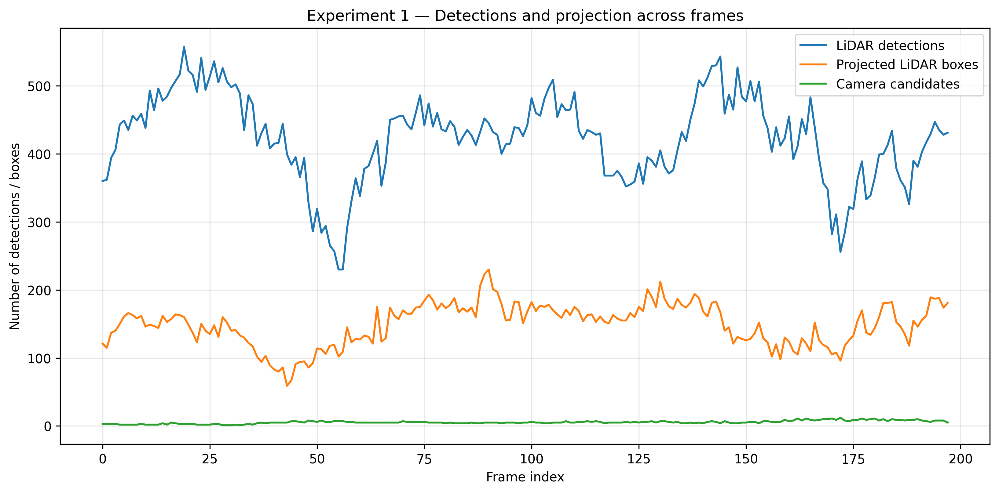

fig2_matches_per_frame.png


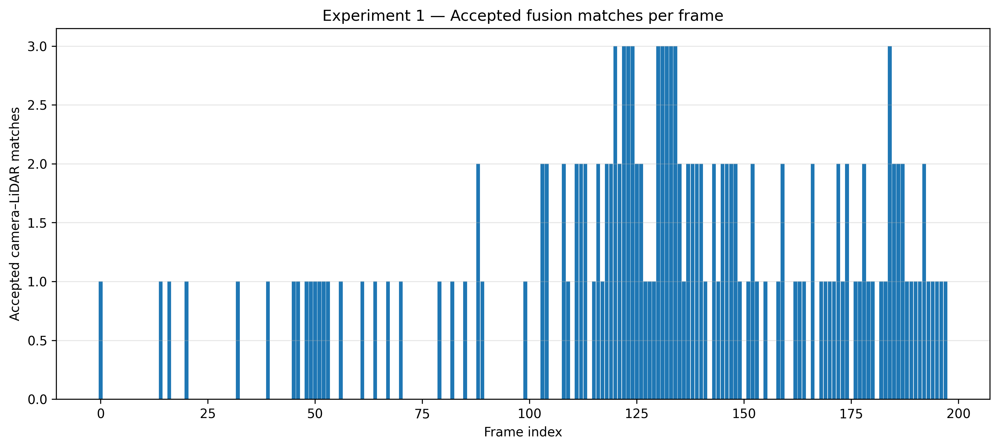

fig3_matched_iou_distribution.png


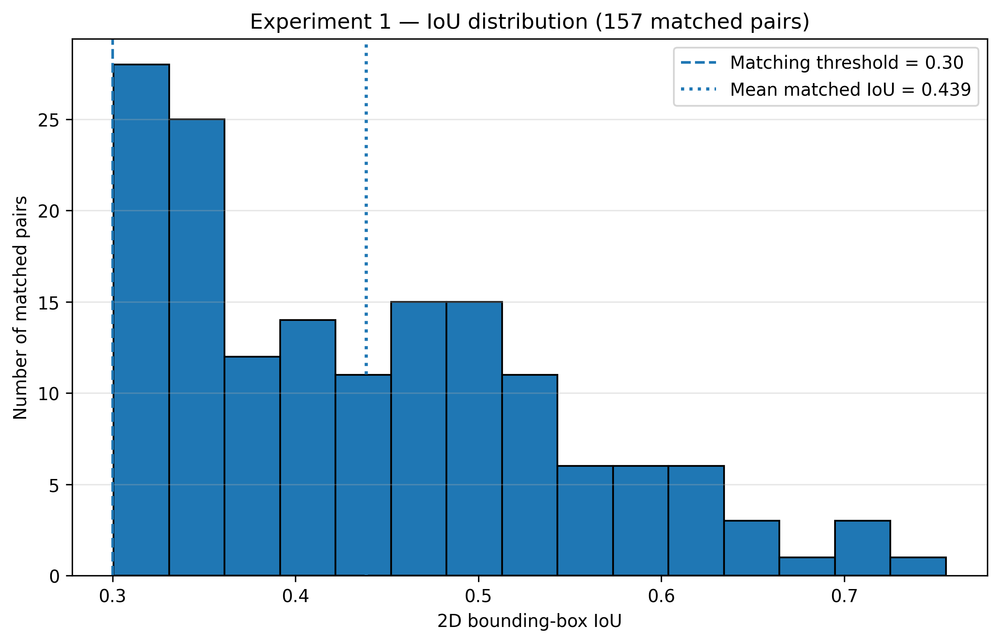

fig4_aggregate_counts.png


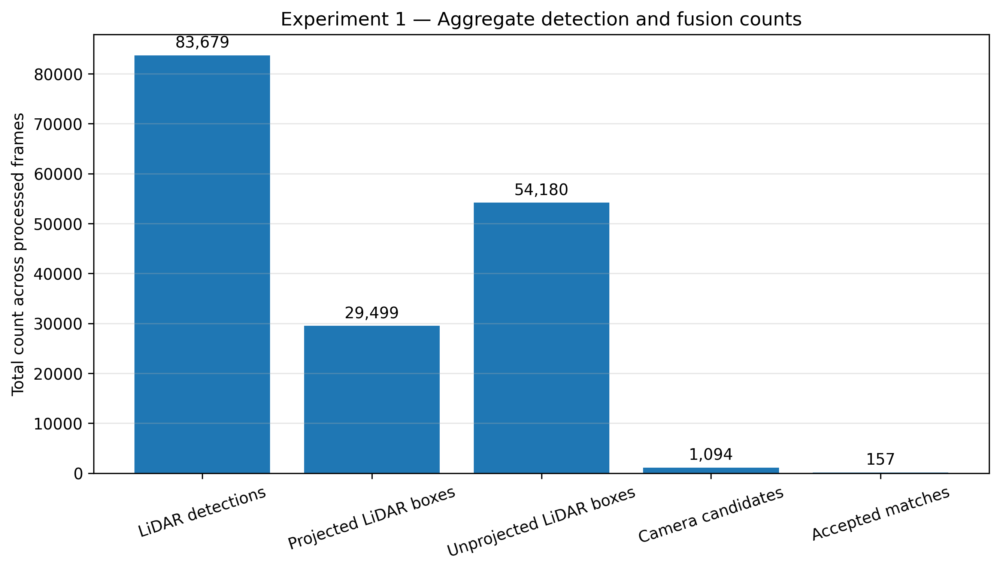

fig5_runtime_per_frame.png


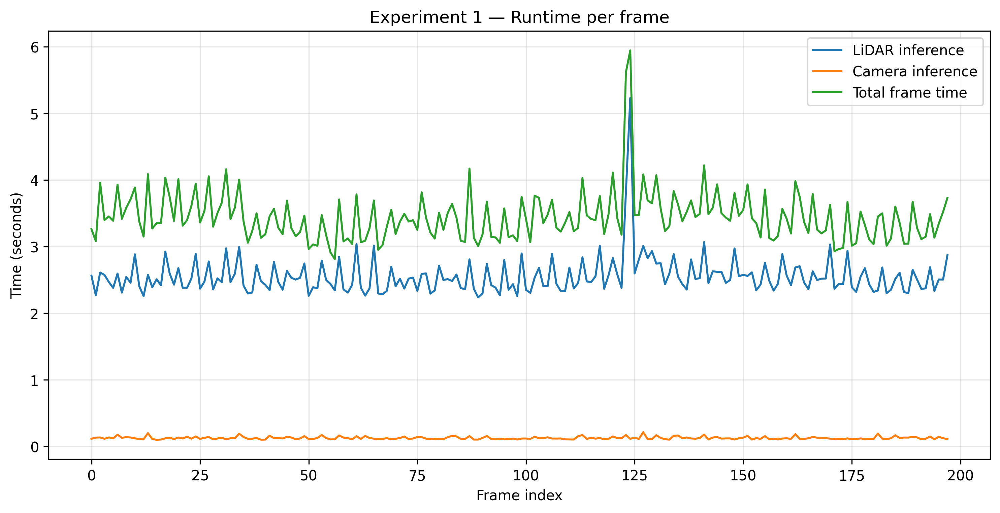

In [221]:
# Displays all generated graph images.
from IPython.display import display, Image

for graph in sorted((RESULTS_DIR / "graphs").glob("*.png")):
    print(graph.name)
    display(Image(filename=str(graph)))